# Entrenamiento de modelos Multicanal

**Maestría en Inteligencia Artificial MAIA**

***Estudiantes:***
- María José García (mj.garciab1@uniandes.edu.co)
- Daniel Osuna (d.osuna@uniandes.edu.co)
- Gabriel Vizcaya (g.vizcaya@uniandes.edu.co)
- Joel Vargas (js.vargasl1@uniandes.edu.co)

Entrenamiento supervisado con `XGBClassifier`, `Random Forest`, `Arbol de Decisiones`y `LightGBM` usando `train_multicanal.csv` y `test_multicanal.csv`. El dataset multicanal conserva un único esquema de columnas para soportar inferencia cuando alguno de los canales `EEG` está presente y `EOG horizontal` opcional. La evaluación se reporta de forma global y por combinación de canales (`channel_combo`).

In [6]:
import json
import os
import sys
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn
import numpy as np
import pandas as pd
import seaborn as sns
from dotenv import load_dotenv
from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    cohen_kappa_score,
    confusion_matrix,
    f1_score,
    precision_recall_fscore_support,
)
from sklearn.model_selection import RandomizedSearchCV, StratifiedGroupKFold
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier

project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))
from src.data.segmentation import CLASS_NAMES, INT_TO_CLASS


warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")

## Configuración

El entrenamiento excluye identificadores y columnas de control que pueden generar fuga de información (`recording_id`, `subject_code`, `split`, `epoch_idx_in_recording`). Sí se conservan las columnas de disponibilidad de canales (`has_eeg_pz_oz`, `has_eog_horizontal`), `channel_count` y una codificación one-hot de `channel_combo`, porque esas variables representan qué señales están disponibles en inferencia.

In [ ]:
RANDOM_STATE = 42
CV_SPLITS = 5
N_ITER_SEARCH = 10
SCORING = "f1_macro"

TARGET_COLUMN = "y"
ID_COLUMNS = ["recording_id", "subject_code"]
CONTROL_COLUMNS = ["split", "epoch_idx_in_recording"]
CATEGORICAL_COLUMNS = ["channel_combo"]

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "data" / "processed" / "train_multicanal.csv").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data" / "processed"
MODEL_DIR = PROJECT_ROOT / "modelos"
MODEL_DIR.mkdir(exist_ok=True)

TRAIN_PATH = DATA_DIR / "train_multicanal.csv"
TEST_PATH = DATA_DIR / "test_multicanal.csv"

COMPARISON_PATH = MODEL_DIR / "model_comparison_multicanal.csv"
COMPARISON_BY_COMBO_PATH = MODEL_DIR / "model_comparison_by_channel_combo_multicanal.csv"


def get_artifact_paths(model_slug):
    """Rutas de artefactos de un modelo, p. ej. `best-xgboost-multicanal.joblib`."""
    return {
        "joblib": MODEL_DIR / f"best-{model_slug}-multicanal.joblib",
        "info": MODEL_DIR / f"model_info_{model_slug}_multicanal.json",
        "metrics_by_combo": MODEL_DIR / f"metrics_by_channel_combo_{model_slug}_multicanal.csv",
        "per_class_by_combo": MODEL_DIR / f"per_class_metrics_by_channel_combo_{model_slug}_multicanal.csv",
        "feature_importance": MODEL_DIR / f"feature_importance_{model_slug}_multicanal.csv",
    }

## Carga de datos

In [3]:
train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

print(f"Train shape: {train_df.shape}")
print(f"Test shape:  {test_df.shape}")

display(train_df.head())
display(train_df[TARGET_COLUMN].value_counts().sort_index().rename("train_count"))
display(test_df[TARGET_COLUMN].value_counts().sort_index().rename("test_count"))
display(train_df["channel_combo"].value_counts().rename("train_rows_by_combo"))
display(test_df["channel_combo"].value_counts().rename("test_rows_by_combo"))

Train shape: (901632, 52)
Test shape:  (271242, 52)


,channel_combo,channel_count,split,epoch_idx_in_recording,has_eeg_fpz_cz,has_eeg_pz_oz,has_eog_horizontal,recording_id,subject_code,y,...,EOG_horizontal__delta_alpha_ratio,EOG_horizontal__delta_power_abs,EOG_horizontal__delta_power_rel,EOG_horizontal__sef95,EOG_horizontal__sigma_power_abs,EOG_horizontal__sigma_power_rel,EOG_horizontal__spectral_entropy,EOG_horizontal__theta_alpha_ratio,EOG_horizontal__theta_power_abs,EOG_horizontal__theta_power_rel
0,eeg_fpz_cz,1,train,0,True,False,False,SC4001E0,0,W,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,eeg_fpz_cz,1,train,1,True,False,False,SC4001E0,0,W,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,eeg_fpz_cz,1,train,2,True,False,False,SC4001E0,0,W,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,eeg_fpz_cz,1,train,3,True,False,False,SC4001E0,0,W,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,eeg_fpz_cz,1,train,4,True,False,False,SC4001E0,0,W,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


y
N1      98670
N2     321558
N3      63474
REM    120540
W      297390
Name: train_count, dtype: int64

y
N1     30462
N2     93234
N3     14760
REM    34470
W      98316
Name: test_count, dtype: int64

channel_combo
eeg_fpz_cz                               150272
eeg_pz_oz                                150272
eeg_fpz_cz__eeg_pz_oz                    150272
eeg_fpz_cz__eog_horizontal               150272
eeg_pz_oz__eog_horizontal                150272
eeg_fpz_cz__eeg_pz_oz__eog_horizontal    150272
Name: train_rows_by_combo, dtype: int64

channel_combo
eeg_fpz_cz                               45207
eeg_pz_oz                                45207
eeg_fpz_cz__eeg_pz_oz                    45207
eeg_fpz_cz__eog_horizontal               45207
eeg_pz_oz__eog_horizontal                45207
eeg_fpz_cz__eeg_pz_oz__eog_horizontal    45207
Name: test_rows_by_combo, dtype: int64

## Preparación de matrices

In [4]:
missing_columns = set(train_df.columns) ^ set(test_df.columns)
if missing_columns:
    raise ValueError(f"Train y test no tienen las mismas columnas: {missing_columns}")

excluded_columns = [TARGET_COLUMN, *ID_COLUMNS, *CONTROL_COLUMNS]
base_feature_columns = [column for column in train_df.columns if column not in excluded_columns]

X_train_raw = train_df[base_feature_columns].copy()
X_test_raw = test_df[base_feature_columns].copy()

X_train = pd.get_dummies(X_train_raw, columns=CATEGORICAL_COLUMNS, dtype=np.int8)
X_test = pd.get_dummies(X_test_raw, columns=CATEGORICAL_COLUMNS, dtype=np.int8)
X_train, X_test = X_train.align(X_test, join="left", axis=1, fill_value=0)

for df in (X_train, X_test):
    bool_columns = df.select_dtypes(include="bool").columns
    df[bool_columns] = df[bool_columns].astype(np.int8)

feature_columns = X_train.columns.tolist()

y_train_names = train_df[TARGET_COLUMN].map(INT_TO_CLASS).fillna(train_df[TARGET_COLUMN]).astype(str)
y_test_names = test_df[TARGET_COLUMN].map(INT_TO_CLASS).fillna(test_df[TARGET_COLUMN]).astype(str)

label_encoder = LabelEncoder()
label_encoder.fit(CLASS_NAMES)
y_train = label_encoder.transform(y_train_names)
y_test = label_encoder.transform(y_test_names)
class_labels = np.array(CLASS_NAMES)

groups = train_df["subject_code"].astype(str).to_numpy()
sample_weights = compute_sample_weight(class_weight="balanced", y=y_train)

print(f"Número de features: {len(feature_columns)}")
print(f"Clases: {class_labels.tolist()}")
print(f"Número de pacientes/grupos en train: {pd.Series(groups).nunique()}")
print(f"Columnas excluidas: {excluded_columns}")
display(pd.Series(feature_columns, name="features"))

Número de features: 52
Clases: ['W', 'N1', 'N2', 'N3', 'REM']
Número de pacientes/grupos en train: 62
Columnas excluidas: ['y', 'recording_id', 'subject_code', 'split', 'epoch_idx_in_recording']


0                                         channel_count
1                                        has_eeg_fpz_cz
2                                         has_eeg_pz_oz
3                                    has_eog_horizontal
4                           EEG_Fpz-Cz__alpha_power_abs
5                           EEG_Fpz-Cz__alpha_power_rel
6                            EEG_Fpz-Cz__beta_power_abs
7                            EEG_Fpz-Cz__beta_power_rel
8                         EEG_Fpz-Cz__delta_alpha_ratio
9                           EEG_Fpz-Cz__delta_power_abs
10                          EEG_Fpz-Cz__delta_power_rel
11                                    EEG_Fpz-Cz__sef95
12                          EEG_Fpz-Cz__sigma_power_abs
13                          EEG_Fpz-Cz__sigma_power_rel
14                         EEG_Fpz-Cz__spectral_entropy
15                        EEG_Fpz-Cz__theta_alpha_ratio
16                          EEG_Fpz-Cz__theta_power_abs
17                          EEG_Fpz-Cz__theta_po

In [5]:
X_train.head()

,channel_count,has_eeg_fpz_cz,has_eeg_pz_oz,has_eog_horizontal,EEG_Fpz-Cz__alpha_power_abs,EEG_Fpz-Cz__alpha_power_rel,EEG_Fpz-Cz__beta_power_abs,EEG_Fpz-Cz__beta_power_rel,EEG_Fpz-Cz__delta_alpha_ratio,EEG_Fpz-Cz__delta_power_abs,...,EOG_horizontal__spectral_entropy,EOG_horizontal__theta_alpha_ratio,EOG_horizontal__theta_power_abs,EOG_horizontal__theta_power_rel,channel_combo_eeg_fpz_cz,channel_combo_eeg_fpz_cz__eeg_pz_oz,channel_combo_eeg_fpz_cz__eeg_pz_oz__eog_horizontal,channel_combo_eeg_fpz_cz__eog_horizontal,channel_combo_eeg_pz_oz,channel_combo_eeg_pz_oz__eog_horizontal
0,1,1,0,0,5.486738,0.013604,10.381680,0.025741,63.606533,348.99237,...,0.0,0.0,0.0,0.0,1,0,0,0,0,0
1,1,1,0,0,4.664630,0.008347,10.181633,0.018218,105.300140,491.18613,...,0.0,0.0,0.0,0.0,1,0,0,0,0,0
2,1,1,0,0,5.123155,0.006255,8.309876,0.010146,142.967540,732.44480,...,0.0,0.0,0.0,0.0,1,0,0,0,0,0
3,1,1,0,0,6.026664,0.009737,16.675737,0.026941,89.450554,539.08844,...,0.0,0.0,0.0,0.0,1,0,0,0,0,0
4,1,1,0,0,5.224161,0.010322,10.000229,0.019758,84.824066,443.13455,...,0.0,0.0,0.0,0.0,1,0,0,0,0,0


## Búsqueda de hiperparámetros con validación cruzada

Los cuatro modelos (`XGBoost`, `LightGBM`, `Random Forest` y `Árbol de Decisión`) se entrenan con el mismo protocolo para que la comparación sea justa:

- `RandomizedSearchCV` con `N_ITER_SEARCH` combinaciones por modelo.
- CV estratificada por clase y agrupada por `subject_code` (`StratifiedGroupKFold`). Así, todas las épocas de un mismo paciente quedan completas en train o validation dentro de cada fold. Los folds son idénticos para todos los modelos.
- Pesos de muestra balanceados (`sample_weight`) para compensar el desbalance de clases.
- Selección del mejor modelo por `f1_macro` y evaluación final en `test_multicanal.csv`.

Las funciones siguientes encapsulan la búsqueda, la evaluación y el guardado de artefactos, para aplicar exactamente el mismo flujo a cada modelo.

In [6]:
cv = StratifiedGroupKFold(
    n_splits=CV_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE,
)

LABEL_IDS = label_encoder.transform(class_labels)
CV_SUMMARY_COLUMNS = [
    "rank_test_score",
    "mean_test_score",
    "std_test_score",
    "mean_train_score",
    "std_train_score",
    "params",
]

# Resultados de cada modelo para la comparación final.
results = {}


def run_search(model_name, estimator, param_distributions):
    search = RandomizedSearchCV(
        estimator=estimator,
        param_distributions=param_distributions,
        n_iter=N_ITER_SEARCH,
        scoring=SCORING,
        cv=cv,
        verbose=2,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        refit=True,
        return_train_score=True,
    )
    search.fit(X_train, y_train, groups=groups, sample_weight=sample_weights)

    print(f"[{model_name}] Mejor {SCORING} CV: {search.best_score_}")
    print("Mejores hiperparámetros:")
    display(search.best_params_)
    return search


def show_cv_results(search, top_n=10):
    cv_results = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
    display(cv_results[CV_SUMMARY_COLUMNS].head(top_n))
    return cv_results

In [ ]:
def evaluate_predictions(y_true, y_hat, labels, prefix=None):
    return {
        "channel_combo": prefix,
        "support": int(len(y_true)),
        "accuracy": accuracy_score(y_true, y_hat),
        "macro_f1": f1_score(y_true, y_hat, average="macro", zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_hat),
        "cohens_kappa": cohen_kappa_score(y_true, y_hat),
    }


def evaluate_global(model_name, search):
    y_pred = search.best_estimator_.predict(X_test)

    precision, recall, f1, support = precision_recall_fscore_support(
        y_test,
        y_pred,
        labels=LABEL_IDS,
        zero_division=0,
    )

    metrics = {
        "accuracy": accuracy_score(y_test, y_pred),
        "macro_f1": f1_score(y_test, y_pred, average="macro", zero_division=0),
        "balanced_accuracy": balanced_accuracy_score(y_test, y_pred),
        "cohens_kappa": cohen_kappa_score(y_test, y_pred),
        "best_cv_macro_f1": search.best_score_,
        "best_params": search.best_params_,
    }

    per_class_metrics = pd.DataFrame(
        {
            "class": class_labels,
            "precision_per_class": precision,
            "recall_per_class": recall,
            "f1_per_class": f1,
            "support": support,
        }
    )

    print(f"=== {model_name} - evaluación global en test ===")
    display(pd.Series(metrics, name="value"))
    display(per_class_metrics)
    print(classification_report(y_test, y_pred, target_names=[str(label) for label in class_labels], zero_division=0))
    return y_pred, metrics, per_class_metrics


def evaluate_by_combo(model_name, y_pred):
    combo_metric_rows = []
    combo_per_class_rows = []

    test_eval_df = test_df[["channel_combo", "recording_id", "subject_code", TARGET_COLUMN]].copy()
    test_eval_df["y_true"] = y_test
    test_eval_df["y_pred"] = y_pred

    combo_metric_rows.append(evaluate_predictions(y_test, y_pred, LABEL_IDS, prefix="overall"))

    for combo_name, combo_df in test_eval_df.groupby("channel_combo", sort=True):
        combo_y_true = combo_df["y_true"].to_numpy()
        combo_y_pred = combo_df["y_pred"].to_numpy()
        combo_metric_rows.append(evaluate_predictions(combo_y_true, combo_y_pred, LABEL_IDS, prefix=combo_name))

        p, r, f, s = precision_recall_fscore_support(
            combo_y_true,
            combo_y_pred,
            labels=LABEL_IDS,
            zero_division=0,
        )
        for class_name, precision_i, recall_i, f1_i, support_i in zip(class_labels, p, r, f, s):
            combo_per_class_rows.append(
                {
                    "channel_combo": combo_name,
                    "class": class_name,
                    "precision_per_class": precision_i,
                    "recall_per_class": recall_i,
                    "f1_per_class": f1_i,
                    "support": support_i,
                }
            )

    metrics_by_combo = pd.DataFrame(combo_metric_rows).sort_values("channel_combo")
    per_class_by_combo = pd.DataFrame(combo_per_class_rows).sort_values(["channel_combo", "class"])

    display(metrics_by_combo)
    display(per_class_by_combo)

    plt.figure(figsize=(10, 5))
    sns.barplot(data=metrics_by_combo[metrics_by_combo["channel_combo"] != "overall"], x="channel_combo", y="macro_f1", color="#4C78A8")
    plt.title(f"Macro F1 por combinación de canales - {model_name}")
    plt.xlabel("Combinación de canales")
    plt.ylabel("Macro F1")
    plt.xticks(rotation=30, ha="right")
    plt.ylim(0, 1)
    plt.tight_layout()
    plt.show()
    return test_eval_df, metrics_by_combo, per_class_by_combo


def plot_confusion_matrices(model_name, test_eval_df):
    conf_matrix = confusion_matrix(test_eval_df["y_true"], test_eval_df["y_pred"], labels=LABEL_IDS)
    conf_matrix_df = pd.DataFrame(conf_matrix, index=class_labels, columns=class_labels)

    plt.figure(figsize=(8, 6))
    sns.heatmap(conf_matrix_df, annot=True, fmt="d", cmap="Blues", cbar=False)
    plt.title(f"Matriz de confusión global - {model_name} multicanal")
    plt.xlabel("Predicción")
    plt.ylabel("Clase real")
    plt.tight_layout()
    plt.show()
    display(conf_matrix_df)

    for combo_name, combo_df in test_eval_df.groupby("channel_combo", sort=True):
        combo_conf_matrix = confusion_matrix(
            combo_df["y_true"],
            combo_df["y_pred"],
            labels=LABEL_IDS,
        )
        combo_conf_matrix_df = pd.DataFrame(combo_conf_matrix, index=class_labels, columns=class_labels)
        plt.figure(figsize=(7, 5))
        sns.heatmap(combo_conf_matrix_df, annot=True, fmt="d", cmap="Blues", cbar=False)
        plt.title(f"Matriz de confusión - {model_name} - {combo_name}")
        plt.xlabel("Predicción")
        plt.ylabel("Clase real")
        plt.tight_layout()
        plt.show()
        display(combo_conf_matrix_df)


def plot_feature_importance(model_name, model, top_n=30):
    feature_importance = pd.DataFrame(
        {
            "feature": feature_columns,
            "importance": model.feature_importances_,
        }
    ).sort_values("importance", ascending=False)

    plt.figure(figsize=(10, 10))
    sns.barplot(data=feature_importance.head(top_n), x="importance", y="feature", color="#4C78A8")
    plt.title(f"Top {top_n} importancia de variables - {model_name} multicanal")
    plt.xlabel("Importancia")
    plt.ylabel("")
    plt.tight_layout()
    plt.show()

    display(feature_importance)
    return feature_importance


def save_artifacts(model_name, model_slug, search, metrics, metrics_by_combo, per_class_by_combo, feature_importance):
    paths = get_artifact_paths(model_slug)
    best_model = search.best_estimator_

    joblib.dump(
        {
            "model": best_model,
            "label_encoder": label_encoder,
            "feature_columns": feature_columns,
            "excluded_columns": excluded_columns,
            "categorical_columns": CATEGORICAL_COLUMNS,
            "class_labels": class_labels.tolist(),
        },
        paths["joblib"],
    )

    feature_importance.to_csv(paths["feature_importance"], index=False)
    metrics_by_combo.to_csv(paths["metrics_by_combo"], index=False)
    per_class_by_combo.to_csv(paths["per_class_by_combo"], index=False)

    info = {
        "model": model_name,
        **metrics,
        "feature_columns": feature_columns,
        "excluded_columns": excluded_columns,
        "metrics_by_channel_combo": metrics_by_combo.to_dict(orient="records"),
    }

    with open(paths["info"], "w") as f:
        # default=str cubre valores numpy o None dentro de best_params.
        json.dump(info, f, indent=4, default=str)

    results[model_name] = {
        "slug": model_slug,
        "search": search,
        "metrics": metrics,
        "metrics_by_combo": metrics_by_combo,
    }

    return paths

## Modelo 1: XGBoost

Gradient boosting con árboles (`tree_method="hist"`). Se exploran número de árboles, profundidad, tasa de aprendizaje y regularización.

### Búsqueda de hiperparámetros

In [8]:
xgb_model = XGBClassifier(
    objective="multi:softprob",
    num_class=len(class_labels),
    eval_metric="mlogloss",
    tree_method="hist",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

xgb_param_distributions = {
    "n_estimators": [200, 300, 500, 700],
    "max_depth": [3, 4, 5, 6, 8],
    "learning_rate": [0.01, 0.03, 0.05, 0.08, 0.1],
    "gamma": [0, 0.1, 0.3, 0.5, 1.0],
}

xgb_search = run_search("XGBoost", xgb_model, xgb_param_distributions)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
[CV] END gamma=0.5, learning_rate=0.08, max_depth=3, n_estimators=300; total time= 1.6min
[CV] END gamma=0.5, learning_rate=0.08, max_depth=3, n_estimators=300; total time= 1.6min
[CV] END gamma=0.5, learning_rate=0.08, max_depth=3, n_estimators=300; total time= 1.6min
[CV] END gamma=0.5, learning_rate=0.08, max_depth=3, n_estimators=300; total time= 1.6min
[CV] END gamma=0.5, learning_rate=0.08, max_depth=3, n_estimators=300; total time= 1.6min
[CV] END gamma=0, learning_rate=0.08, max_depth=6, n_estimators=300; total time= 2.4min
[CV] END gamma=0, learning_rate=0.08, max_depth=6, n_estimators=300; total time= 2.4min
[CV] END gamma=0, learning_rate=0.08, max_depth=6, n_estimators=300; total time= 2.4min
[CV] END gamma=0, learning_rate=0.08, max_depth=6, n_estimators=300; total time= 2.4min
[CV] END gamma=0, learning_rate=0.08, max_depth=6, n_estimators=300; total time= 2.4min
[CV] END gamma=0.5, learning_rate=0.08, max_depth

{'n_estimators': 500, 'max_depth': 5, 'learning_rate': 0.05, 'gamma': 1.0}

In [9]:
xgb_cv_results = show_cv_results(xgb_search)

,rank_test_score,mean_test_score,std_test_score,mean_train_score,std_train_score,params
9,1,0.683577,0.013926,0.766584,0.003146,"{'n_estimators': 500, 'max_depth': 5, 'learnin..."
1,2,0.683228,0.013923,0.788139,0.003116,"{'n_estimators': 300, 'max_depth': 6, 'learnin..."
2,3,0.682090,0.015404,0.813330,0.002577,"{'n_estimators': 500, 'max_depth': 6, 'learnin..."
3,4,0.682076,0.015024,0.805895,0.002597,"{'n_estimators': 700, 'max_depth': 6, 'learnin..."
8,5,0.681944,0.012647,0.751039,0.003170,"{'n_estimators': 200, 'max_depth': 5, 'learnin..."
5,6,0.679981,0.014976,0.825962,0.002312,"{'n_estimators': 500, 'max_depth': 6, 'learnin..."
6,7,0.678699,0.017268,0.843157,0.002664,"{'n_estimators': 300, 'max_depth': 8, 'learnin..."
0,8,0.675372,0.010653,0.724412,0.003723,"{'n_estimators': 300, 'max_depth': 3, 'learnin..."
7,9,0.653953,0.009750,0.693066,0.004061,"{'n_estimators': 200, 'max_depth': 4, 'learnin..."
4,10,0.622529,0.009217,0.651678,0.006780,"{'n_estimators': 200, 'max_depth': 4, 'learnin..."


### Evaluación global en test y por combinación de canales

=== XGBoost - evaluación global en test ===


accuracy                                                      0.710627
macro_f1                                                      0.650126
balanced_accuracy                                             0.696026
cohens_kappa                                                  0.611487
best_cv_macro_f1                                              0.683577
best_params          {'n_estimators': 500, 'max_depth': 5, 'learnin...
Name: value, dtype: object

,class,precision_per_class,recall_per_class,f1_per_class,support
0,W,0.875369,0.843779,0.859284,98316
1,N1,0.325021,0.454402,0.378973,30462
2,N2,0.889925,0.651919,0.752552,93234
3,N3,0.552866,0.891328,0.682436,14760
4,REM,0.526812,0.638700,0.577386,34470


              precision    recall  f1-score   support

           W       0.33      0.45      0.38     30462
          N1       0.89      0.65      0.75     93234
          N2       0.55      0.89      0.68     14760
          N3       0.53      0.64      0.58     34470
         REM       0.88      0.84      0.86     98316

    accuracy                           0.71    271242
   macro avg       0.63      0.70      0.65    271242
weighted avg       0.76      0.71      0.72    271242



,channel_combo,support,accuracy,macro_f1,balanced_accuracy,cohens_kappa
1,eeg_fpz_cz,45207,0.660230,0.601625,0.656740,0.547682
2,eeg_fpz_cz__eeg_pz_oz,45207,0.724888,0.665258,0.706094,0.629939
3,eeg_fpz_cz__eeg_pz_oz__eog_horizontal,45207,0.756830,0.704946,0.747444,0.672129
4,eeg_fpz_cz__eog_horizontal,45207,0.734466,0.681151,0.727535,0.642262
5,eeg_pz_oz,45207,0.667441,0.585462,0.631163,0.553787
6,eeg_pz_oz__eog_horizontal,45207,0.719911,0.663100,0.707178,0.624097
0,overall,271242,0.710627,0.650126,0.696026,0.611487


,channel_combo,class,precision_per_class,recall_per_class,f1_per_class,support
1,eeg_fpz_cz,N1,0.303622,0.426039,0.354561,5077
2,eeg_fpz_cz,N2,0.882546,0.623785,0.730940,15539
3,eeg_fpz_cz,N3,0.499558,0.917886,0.646991,2460
4,eeg_fpz_cz,REM,0.421701,0.547955,0.476609,5745
0,eeg_fpz_cz,W,0.832617,0.768034,0.799022,16386
6,eeg_fpz_cz__eeg_pz_oz,N1,0.327396,0.495962,0.394424,5077
7,eeg_fpz_cz__eeg_pz_oz,N2,0.901188,0.663814,0.764499,15539
8,eeg_fpz_cz__eeg_pz_oz,N3,0.604978,0.908943,0.726446,2460
9,eeg_fpz_cz__eeg_pz_oz,REM,0.526111,0.587467,0.555099,5745
5,eeg_fpz_cz__eeg_pz_oz,W,0.897675,0.874283,0.885825,16386


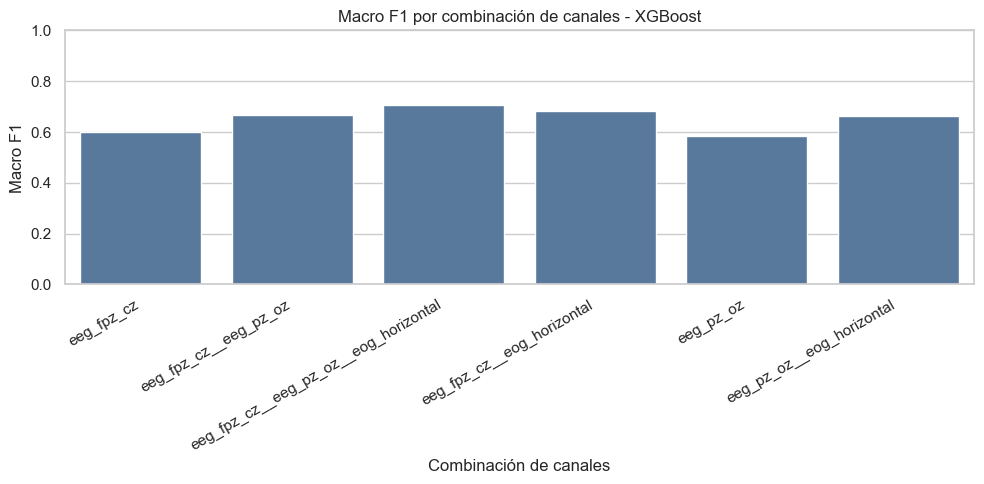

In [10]:
xgb_y_pred, xgb_metrics, xgb_per_class = evaluate_global("XGBoost", xgb_search)
xgb_test_eval_df, xgb_metrics_by_combo, xgb_per_class_by_combo = evaluate_by_combo("XGBoost", xgb_y_pred)

### Matriz de confusión global y por combinación

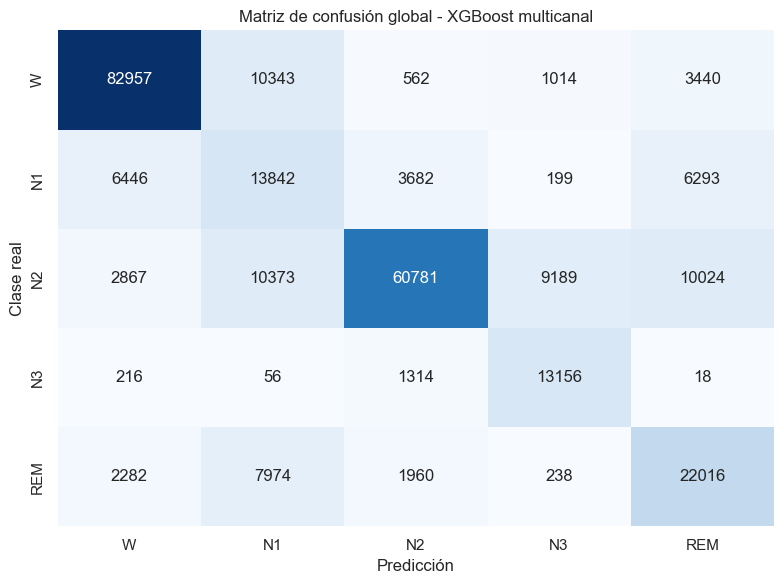

,W,N1,N2,N3,REM
W,82957,10343,562,1014,3440
N1,6446,13842,3682,199,6293
N2,2867,10373,60781,9189,10024
N3,216,56,1314,13156,18
REM,2282,7974,1960,238,22016


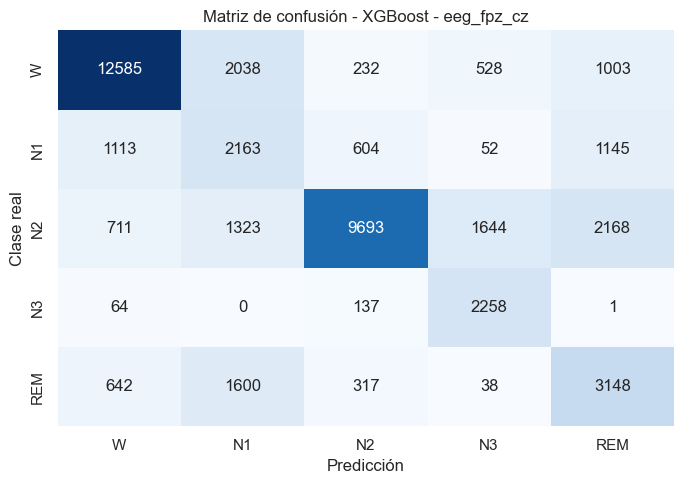

,W,N1,N2,N3,REM
W,12585,2038,232,528,1003
N1,1113,2163,604,52,1145
N2,711,1323,9693,1644,2168
N3,64,0,137,2258,1
REM,642,1600,317,38,3148


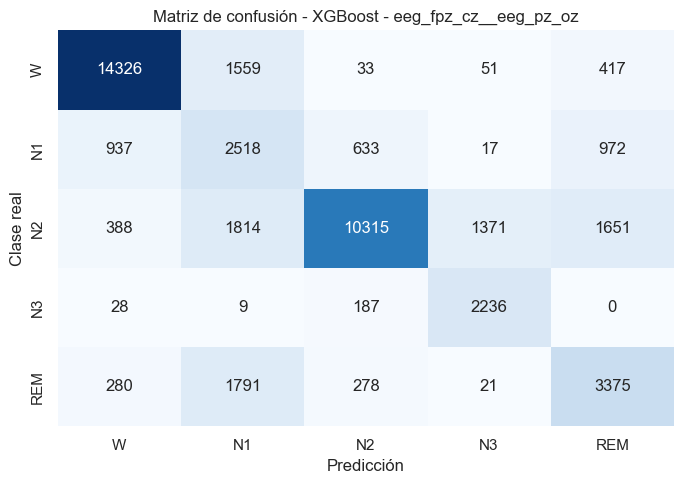

,W,N1,N2,N3,REM
W,14326,1559,33,51,417
N1,937,2518,633,17,972
N2,388,1814,10315,1371,1651
N3,28,9,187,2236,0
REM,280,1791,278,21,3375


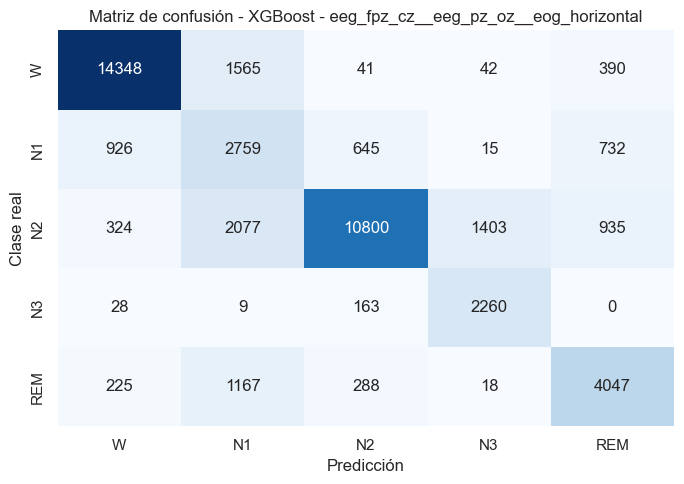

,W,N1,N2,N3,REM
W,14348,1565,41,42,390
N1,926,2759,645,15,732
N2,324,2077,10800,1403,935
N3,28,9,163,2260,0
REM,225,1167,288,18,4047


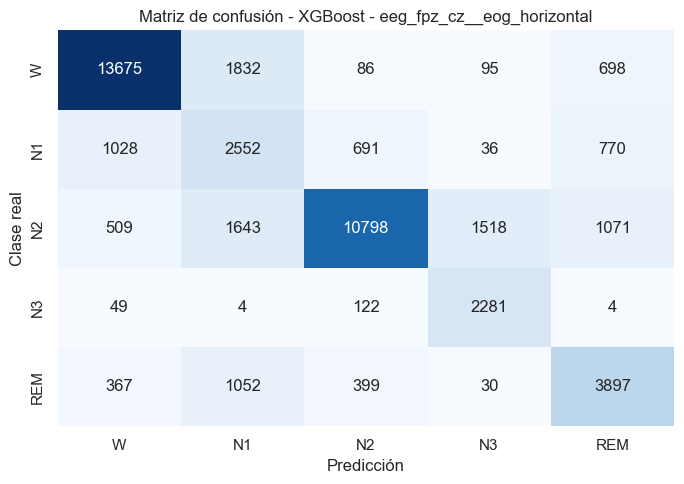

,W,N1,N2,N3,REM
W,13675,1832,86,95,698
N1,1028,2552,691,36,770
N2,509,1643,10798,1518,1071
N3,49,4,122,2281,4
REM,367,1052,399,30,3897


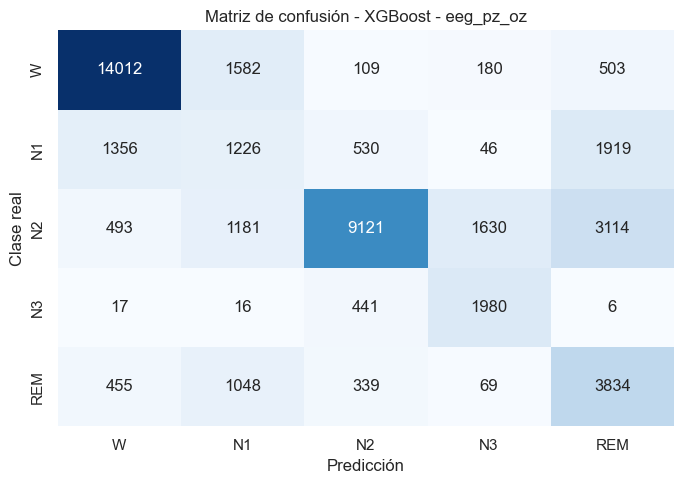

,W,N1,N2,N3,REM
W,14012,1582,109,180,503
N1,1356,1226,530,46,1919
N2,493,1181,9121,1630,3114
N3,17,16,441,1980,6
REM,455,1048,339,69,3834


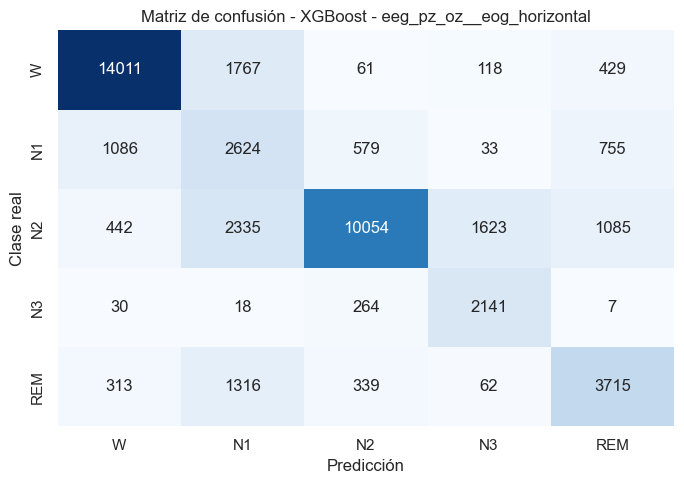

,W,N1,N2,N3,REM
W,14011,1767,61,118,429
N1,1086,2624,579,33,755
N2,442,2335,10054,1623,1085
N3,30,18,264,2141,7
REM,313,1316,339,62,3715


In [11]:
plot_confusion_matrices("XGBoost", xgb_test_eval_df)

### Importancia de variables y guardado de artefactos

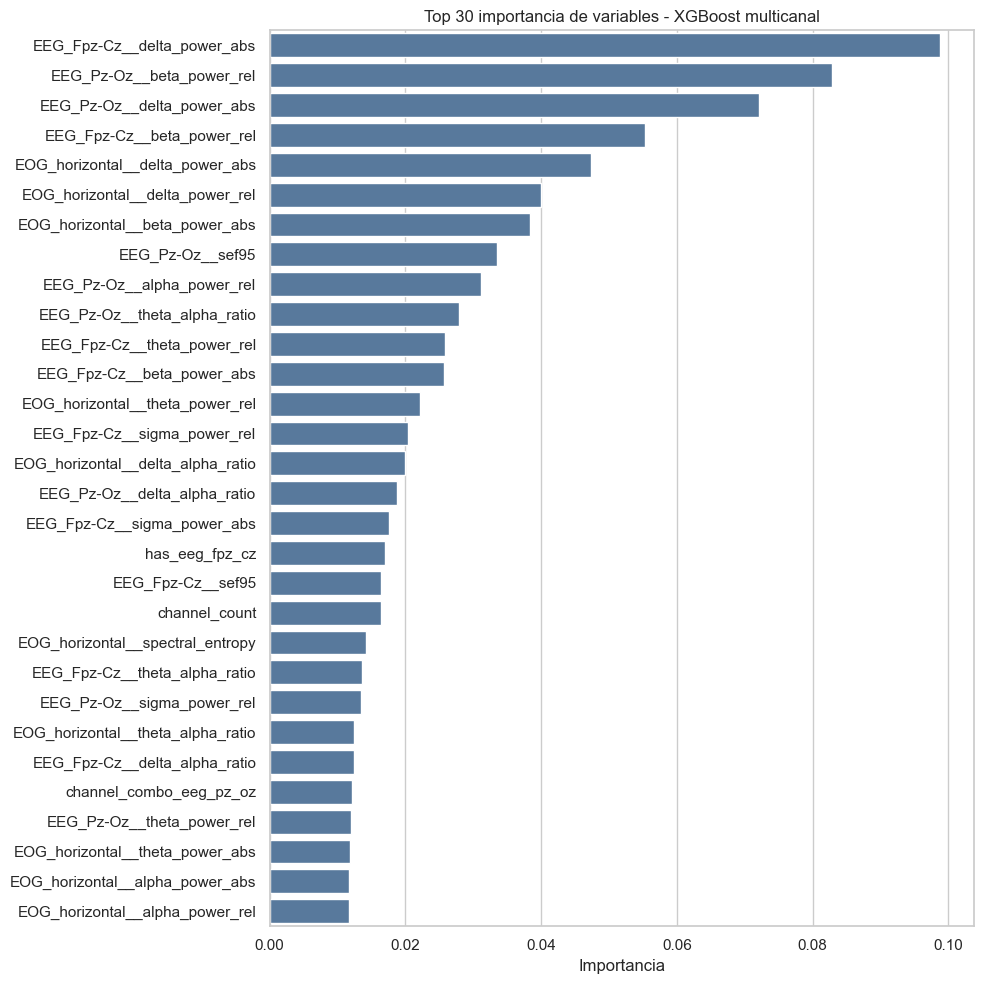

,feature,importance
9,EEG_Fpz-Cz__delta_power_abs,0.098819
21,EEG_Pz-Oz__beta_power_rel,0.082864
23,EEG_Pz-Oz__delta_power_abs,0.072028
7,EEG_Fpz-Cz__beta_power_rel,0.055232
37,EOG_horizontal__delta_power_abs,0.047359
38,EOG_horizontal__delta_power_rel,0.039961
34,EOG_horizontal__beta_power_abs,0.038286
25,EEG_Pz-Oz__sef95,0.033417
19,EEG_Pz-Oz__alpha_power_rel,0.031134
29,EEG_Pz-Oz__theta_alpha_ratio,0.027877


Pipeline joblib guardado en: /Users/joelvargas/Documents/Estudio/MAIA/16_proyecto_despliegue_solucion/proyecto-despliegue-de-soluciones-G10/models/best-xgboost-multicanal.joblib
Info guardada en: /Users/joelvargas/Documents/Estudio/MAIA/16_proyecto_despliegue_solucion/proyecto-despliegue-de-soluciones-G10/models/model_info_xgboost_multicanal.json
Métricas por combinación guardadas en: /Users/joelvargas/Documents/Estudio/MAIA/16_proyecto_despliegue_solucion/proyecto-despliegue-de-soluciones-G10/models/metrics_by_channel_combo_xgboost_multicanal.csv
Modelo XGBoost guardado en: /Users/joelvargas/Documents/Estudio/MAIA/16_proyecto_despliegue_solucion/proyecto-despliegue-de-soluciones-G10/models/best-xgboost-multicanal-model.json


In [ ]:
xgb_feature_importance = plot_feature_importance("XGBoost", xgb_search.best_estimator_)

xgb_paths = save_artifacts(
    "XGBoost",
    "xgboost",
    xgb_search,
    xgb_metrics,
    xgb_metrics_by_combo,
    xgb_per_class_by_combo,
    xgb_feature_importance,
)

# Formato nativo de XGBoost, además del joblib. Se guarda desde el Booster porque
# XGBClassifier.save_model() falla con scikit-learn >= 1.8 (`_estimator_type` undefined).
XGB_MODEL_PATH = MODEL_DIR / "best-xgboost-multicanal-model.json"
xgb_search.best_estimator_.get_booster().save_model(XGB_MODEL_PATH)

## Modelo 2: LightGBM

Gradient boosting con crecimiento de árboles por hoja. Se exploran número de árboles, tasa de aprendizaje, `num_leaves`, profundidad, tamaño mínimo de hoja, submuestreo de filas/columnas y regularización.

### Búsqueda de hiperparámetros

In [13]:
lgbm_model = LGBMClassifier(
    objective="multiclass",
    num_class=len(class_labels),
    subsample_freq=1,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=-1,
)

lgbm_param_distributions = {
    "n_estimators": [200, 300, 500, 700],
    "learning_rate": [0.01, 0.03, 0.05, 0.08, 0.1],
    "num_leaves": [15, 31, 63, 127],
    "max_depth": [-1, 5, 8, 12],
    "min_child_samples": [20, 50, 100, 200],
    "reg_alpha": [0, 0.01, 0.1, 0.5],
    "reg_lambda": [0, 0.5, 1.0, 2.0],
}

lgbm_search = run_search("LightGBM", lgbm_model, lgbm_param_distributions)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
[CV] END learning_rate=0.01, max_depth=-1, min_child_samples=200, n_estimators=300, num_leaves=31, reg_alpha=0.5, reg_lambda=0; total time= 3.1min
[CV] END learning_rate=0.01, max_depth=-1, min_child_samples=200, n_estimators=300, num_leaves=31, reg_alpha=0.5, reg_lambda=0; total time= 3.1min
[CV] END learning_rate=0.01, max_depth=-1, min_child_samples=200, n_estimators=300, num_leaves=31, reg_alpha=0.5, reg_lambda=0; total time= 3.1min
[CV] END learning_rate=0.01, max_depth=-1, min_child_samples=200, n_estimators=300, num_leaves=31, reg_alpha=0.5, reg_lambda=0; total time= 3.2min
[CV] END learning_rate=0.03, max_depth=5, min_child_samples=50, n_estimators=200, num_leaves=15, reg_alpha=0.5, reg_lambda=1.0; total time= 1.1min
[CV] END learning_rate=0.03, max_depth=5, min_child_samples=50, n_estimators=200, num_leaves=15, reg_alpha=0.5, reg_lambda=1.0; total time= 1.2min
[CV] END learning_rate=0.03, max_depth=5, min_child_sampl

{'reg_lambda': 0,
 'reg_alpha': 0.01,
 'num_leaves': 31,
 'n_estimators': 200,
 'min_child_samples': 20,
 'max_depth': 12,
 'learning_rate': 0.05}

In [14]:
lgbm_cv_results = show_cv_results(lgbm_search)

,rank_test_score,mean_test_score,std_test_score,mean_train_score,std_train_score,params
4,1,0.684530,0.013998,0.764496,0.003028,"{'reg_lambda': 0, 'reg_alpha': 0.01, 'num_leav..."
8,2,0.683020,0.016139,0.798099,0.002545,"{'reg_lambda': 2.0, 'reg_alpha': 0.01, 'num_le..."
5,3,0.682742,0.015428,0.805241,0.002600,"{'reg_lambda': 0.5, 'reg_alpha': 0.1, 'num_lea..."
9,4,0.681988,0.016504,0.812673,0.002182,"{'reg_lambda': 2.0, 'reg_alpha': 0, 'num_leave..."
7,5,0.680930,0.012183,0.737348,0.003338,"{'reg_lambda': 1.0, 'reg_alpha': 0.1, 'num_lea..."
2,6,0.674999,0.011316,0.720786,0.003980,"{'reg_lambda': 1.0, 'reg_alpha': 0.5, 'num_lea..."
6,7,0.674350,0.018832,0.865439,0.001792,"{'reg_lambda': 1.0, 'reg_alpha': 0, 'num_leave..."
1,8,0.673086,0.011811,0.723293,0.003561,"{'reg_lambda': 0, 'reg_alpha': 0.5, 'num_leave..."
3,9,0.670900,0.019822,0.895950,0.001929,"{'reg_lambda': 0, 'reg_alpha': 0.5, 'num_leave..."
0,10,0.663451,0.021217,0.929201,0.001463,"{'reg_lambda': 2.0, 'reg_alpha': 0, 'num_leave..."


### Evaluación global en test y por combinación de canales

=== LightGBM - evaluación global en test ===


accuracy                                                      0.711885
macro_f1                                                      0.651369
balanced_accuracy                                             0.696422
cohens_kappa                                                   0.61299
best_cv_macro_f1                                               0.68453
best_params          {'reg_lambda': 0, 'reg_alpha': 0.01, 'num_leav...
Name: value, dtype: object

,class,precision_per_class,recall_per_class,f1_per_class,support
0,W,0.876111,0.843505,0.859498,98316
1,N1,0.324446,0.457816,0.379762,30462
2,N2,0.888844,0.656456,0.755176,93234
3,N3,0.554134,0.889431,0.682843,14760
4,REM,0.533104,0.634900,0.579566,34470


              precision    recall  f1-score   support

           W       0.32      0.46      0.38     30462
          N1       0.89      0.66      0.76     93234
          N2       0.55      0.89      0.68     14760
          N3       0.53      0.63      0.58     34470
         REM       0.88      0.84      0.86     98316

    accuracy                           0.71    271242
   macro avg       0.64      0.70      0.65    271242
weighted avg       0.76      0.71      0.72    271242



,channel_combo,support,accuracy,macro_f1,balanced_accuracy,cohens_kappa
1,eeg_fpz_cz,45207,0.664897,0.606261,0.659496,0.553120
2,eeg_fpz_cz__eeg_pz_oz,45207,0.728427,0.666861,0.707688,0.634272
3,eeg_fpz_cz__eeg_pz_oz__eog_horizontal,45207,0.758555,0.705797,0.747315,0.674107
4,eeg_fpz_cz__eog_horizontal,45207,0.736368,0.682632,0.728106,0.644710
5,eeg_pz_oz,45207,0.663349,0.584984,0.628277,0.548733
6,eeg_pz_oz__eog_horizontal,45207,0.719712,0.663554,0.707646,0.624004
0,overall,271242,0.711885,0.651369,0.696422,0.612990


,channel_combo,class,precision_per_class,recall_per_class,f1_per_class,support
1,eeg_fpz_cz,N1,0.303384,0.420327,0.352407,5077
2,eeg_fpz_cz,N2,0.881260,0.631894,0.736029,15539
3,eeg_fpz_cz,N3,0.512931,0.919106,0.658416,2460
4,eeg_fpz_cz,REM,0.426921,0.553177,0.481917,5745
0,eeg_fpz_cz,W,0.834442,0.772977,0.802534,16386
6,eeg_fpz_cz__eeg_pz_oz,N1,0.328977,0.490841,0.393930,5077
7,eeg_fpz_cz__eeg_pz_oz,N2,0.901278,0.671536,0.769628,15539
8,eeg_fpz_cz__eeg_pz_oz,N3,0.595733,0.908130,0.719485,2460
9,eeg_fpz_cz__eeg_pz_oz,REM,0.539428,0.590601,0.563855,5745
5,eeg_fpz_cz__eeg_pz_oz,W,0.897714,0.877334,0.887407,16386


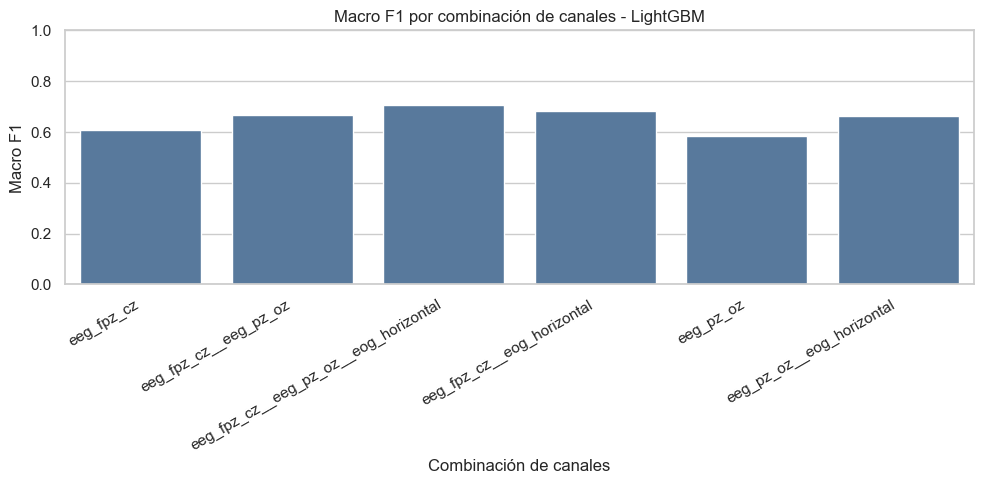

In [15]:
lgbm_y_pred, lgbm_metrics, lgbm_per_class = evaluate_global("LightGBM", lgbm_search)
lgbm_test_eval_df, lgbm_metrics_by_combo, lgbm_per_class_by_combo = evaluate_by_combo("LightGBM", lgbm_y_pred)

### Matriz de confusión global y por combinación

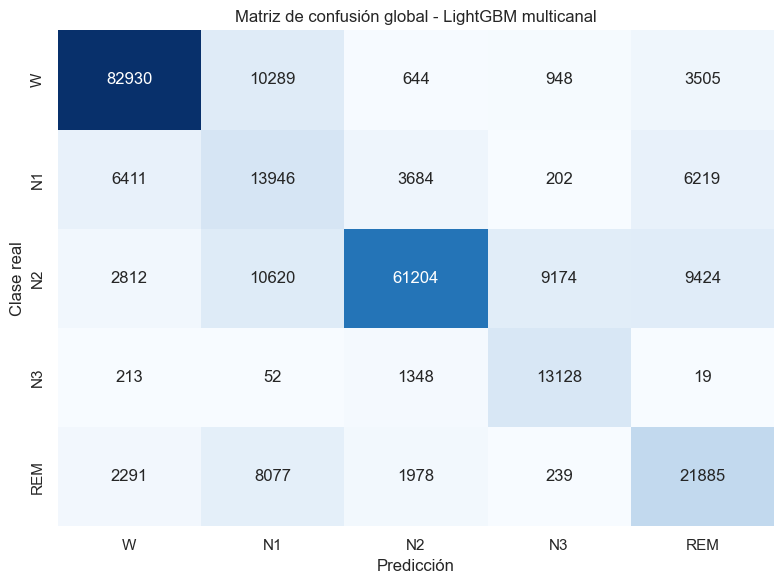

,W,N1,N2,N3,REM
W,82930,10289,644,948,3505
N1,6411,13946,3684,202,6219
N2,2812,10620,61204,9174,9424
N3,213,52,1348,13128,19
REM,2291,8077,1978,239,21885


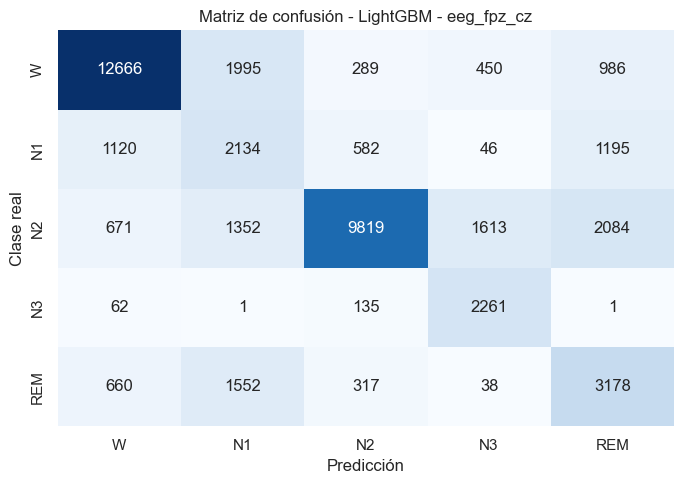

,W,N1,N2,N3,REM
W,12666,1995,289,450,986
N1,1120,2134,582,46,1195
N2,671,1352,9819,1613,2084
N3,62,1,135,2261,1
REM,660,1552,317,38,3178


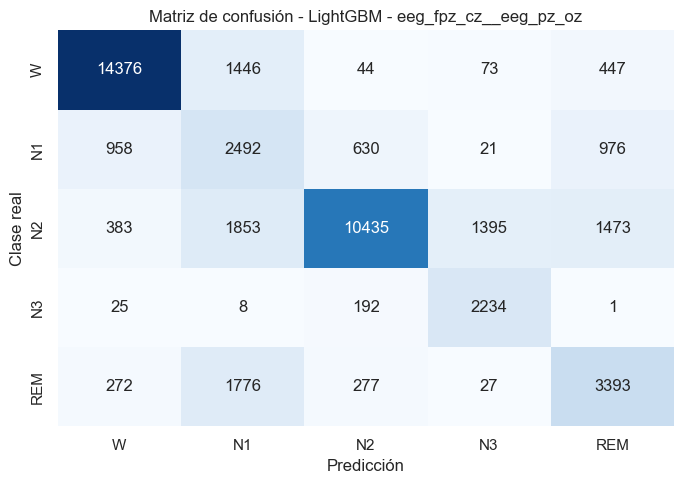

,W,N1,N2,N3,REM
W,14376,1446,44,73,447
N1,958,2492,630,21,976
N2,383,1853,10435,1395,1473
N3,25,8,192,2234,1
REM,272,1776,277,27,3393


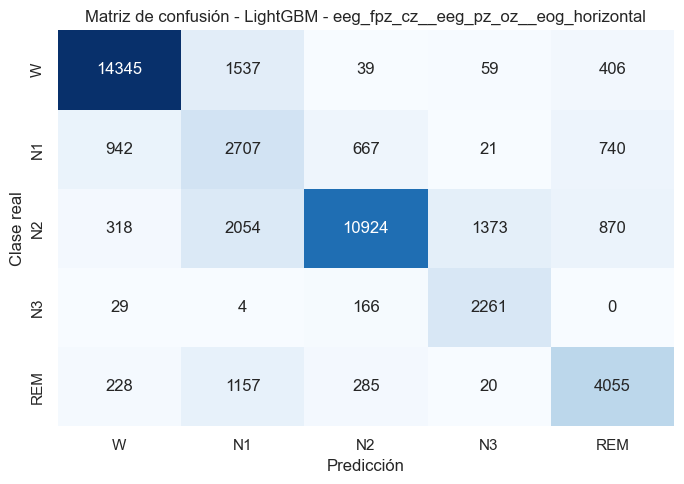

,W,N1,N2,N3,REM
W,14345,1537,39,59,406
N1,942,2707,667,21,740
N2,318,2054,10924,1373,870
N3,29,4,166,2261,0
REM,228,1157,285,20,4055


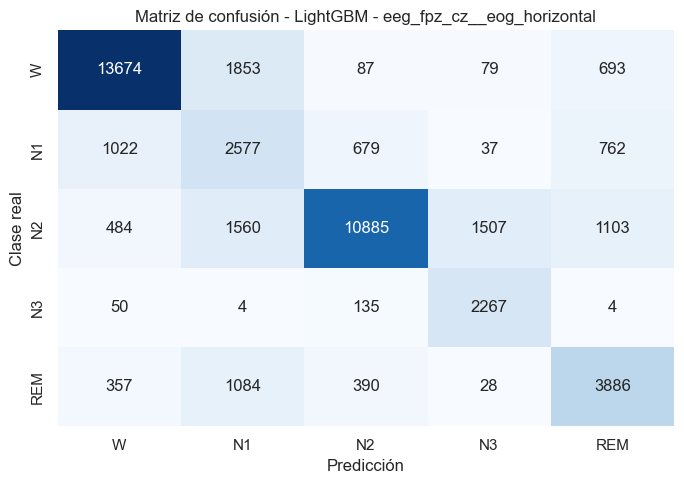

,W,N1,N2,N3,REM
W,13674,1853,87,79,693
N1,1022,2577,679,37,762
N2,484,1560,10885,1507,1103
N3,50,4,135,2267,4
REM,357,1084,390,28,3886


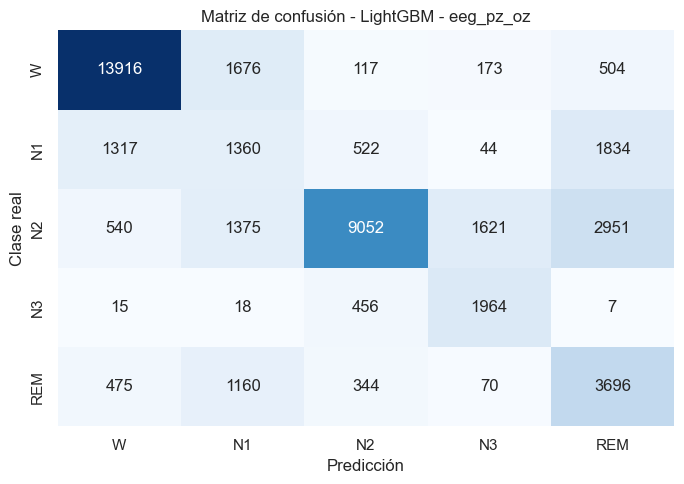

,W,N1,N2,N3,REM
W,13916,1676,117,173,504
N1,1317,1360,522,44,1834
N2,540,1375,9052,1621,2951
N3,15,18,456,1964,7
REM,475,1160,344,70,3696


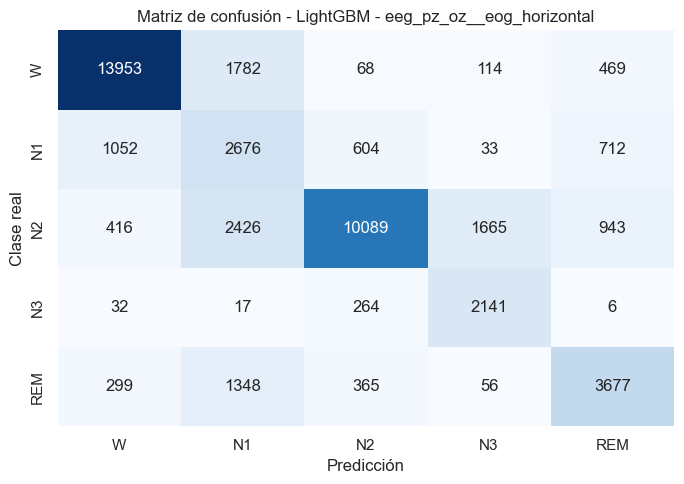

,W,N1,N2,N3,REM
W,13953,1782,68,114,469
N1,1052,2676,604,33,712
N2,416,2426,10089,1665,943
N3,32,17,264,2141,6
REM,299,1348,365,56,3677


In [16]:
plot_confusion_matrices("LightGBM", lgbm_test_eval_df)

### Importancia de variables y guardado de artefactos

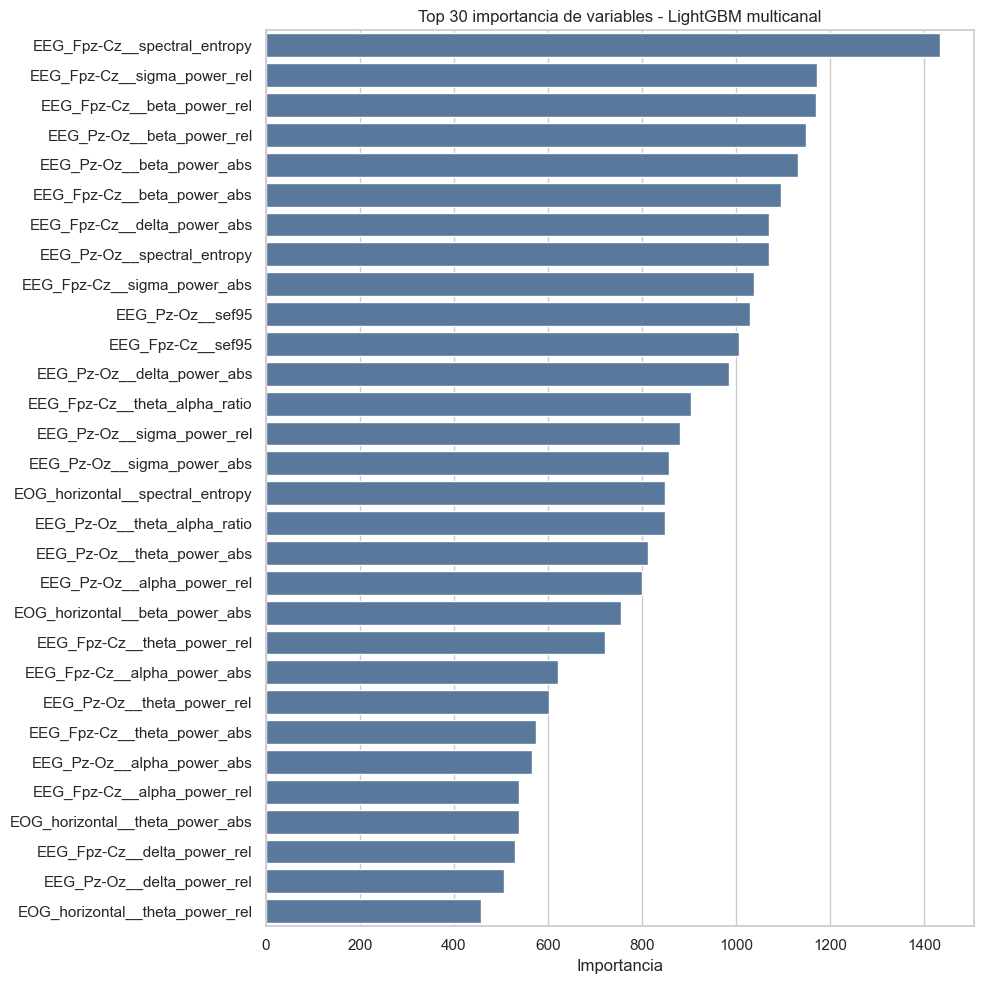

,feature,importance
14,EEG_Fpz-Cz__spectral_entropy,1435
13,EEG_Fpz-Cz__sigma_power_rel,1173
7,EEG_Fpz-Cz__beta_power_rel,1170
21,EEG_Pz-Oz__beta_power_rel,1150
20,EEG_Pz-Oz__beta_power_abs,1132
6,EEG_Fpz-Cz__beta_power_abs,1096
9,EEG_Fpz-Cz__delta_power_abs,1071
28,EEG_Pz-Oz__spectral_entropy,1070
12,EEG_Fpz-Cz__sigma_power_abs,1039
25,EEG_Pz-Oz__sef95,1031


Pipeline joblib guardado en: /Users/joelvargas/Documents/Estudio/MAIA/16_proyecto_despliegue_solucion/proyecto-despliegue-de-soluciones-G10/models/best-lightgbm-multicanal.joblib
Info guardada en: /Users/joelvargas/Documents/Estudio/MAIA/16_proyecto_despliegue_solucion/proyecto-despliegue-de-soluciones-G10/models/model_info_lightgbm_multicanal.json
Métricas por combinación guardadas en: /Users/joelvargas/Documents/Estudio/MAIA/16_proyecto_despliegue_solucion/proyecto-despliegue-de-soluciones-G10/models/metrics_by_channel_combo_lightgbm_multicanal.csv


In [17]:
lgbm_feature_importance = plot_feature_importance("LightGBM", lgbm_search.best_estimator_)

lgbm_paths = save_artifacts(
    "LightGBM",
    "lightgbm",
    lgbm_search,
    lgbm_metrics,
    lgbm_metrics_by_combo,
    lgbm_per_class_by_combo,
    lgbm_feature_importance,
)

## Modelo 3: Random Forest

Ensamble de árboles por bagging. Se exploran número de árboles, profundidad, tamaños mínimos de división/hoja, número de variables por división y fracción de muestras por árbol.

### Búsqueda de hiperparámetros

In [18]:
rf_model = RandomForestClassifier(
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

# `max_samples` limita la fracción de filas por árbol (bootstrap) para mantener
# el tiempo de entrenamiento razonable con ~900k épocas.
rf_param_distributions = {
    "n_estimators": [100, 200],
    "max_depth": [10, 15, 20, 25],
    "min_samples_split": [10, 50, 100],
    "min_samples_leaf": [5, 20, 50],
    "max_features": ["sqrt", "log2"],
    "max_samples": [0.1, 0.2, 0.3],
}

rf_search = run_search("Random Forest", rf_model, rf_param_distributions)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
[CV] END max_depth=25, max_features=log2, max_samples=0.3, min_samples_leaf=20, min_samples_split=100, n_estimators=100; total time= 2.1min
[CV] END max_depth=10, max_features=log2, max_samples=0.2, min_samples_leaf=5, min_samples_split=50, n_estimators=200; total time= 2.1min
[CV] END max_depth=25, max_features=log2, max_samples=0.3, min_samples_leaf=20, min_samples_split=100, n_estimators=100; total time= 2.1min
[CV] END max_depth=25, max_features=log2, max_samples=0.3, min_samples_leaf=20, min_samples_split=100, n_estimators=100; total time= 2.1min
[CV] END max_depth=25, max_features=log2, max_samples=0.3, min_samples_leaf=20, min_samples_split=100, n_estimators=100; total time= 2.1min
[CV] END max_depth=25, max_features=log2, max_samples=0.3, min_samples_leaf=20, min_samples_split=100, n_estimators=100; total time= 2.1min
[CV] END max_depth=10, max_features=log2, max_samples=0.2, min_samples_leaf=5, min_samples_split=50, 

{'n_estimators': 100,
 'min_samples_split': 10,
 'min_samples_leaf': 5,
 'max_samples': 0.3,
 'max_features': 'log2',
 'max_depth': 25}

In [19]:
rf_cv_results = show_cv_results(rf_search)

,rank_test_score,mean_test_score,std_test_score,mean_train_score,std_train_score,params
6,1,0.675976,0.014800,0.846436,0.001559,"{'n_estimators': 100, 'min_samples_split': 10,..."
0,2,0.672900,0.012907,0.760911,0.002497,"{'n_estimators': 100, 'min_samples_split': 100..."
2,3,0.670325,0.013656,0.761236,0.002575,"{'n_estimators': 100, 'min_samples_split': 10,..."
9,4,0.669451,0.012509,0.747441,0.002848,"{'n_estimators': 100, 'min_samples_split': 100..."
7,5,0.669086,0.011850,0.743352,0.002930,"{'n_estimators': 100, 'min_samples_split': 100..."
5,6,0.667730,0.013374,0.733997,0.002846,"{'n_estimators': 200, 'min_samples_split': 100..."
8,7,0.664459,0.012365,0.723749,0.002830,"{'n_estimators': 200, 'min_samples_split': 50,..."
4,8,0.661071,0.012531,0.716343,0.002994,"{'n_estimators': 100, 'min_samples_split': 50,..."
3,9,0.648789,0.011596,0.694446,0.003170,"{'n_estimators': 100, 'min_samples_split': 10,..."
1,10,0.648783,0.012870,0.695319,0.003347,"{'n_estimators': 200, 'min_samples_split': 50,..."


### Evaluación global en test y por combinación de canales

=== Random Forest - evaluación global en test ===


accuracy                                                      0.713204
macro_f1                                                      0.651516
balanced_accuracy                                             0.691689
cohens_kappa                                                  0.613213
best_cv_macro_f1                                              0.675976
best_params          {'n_estimators': 100, 'min_samples_split': 10,...
Name: value, dtype: object

,class,precision_per_class,recall_per_class,f1_per_class,support
0,W,0.874906,0.839212,0.856687,98316
1,N1,0.324977,0.431094,0.370589,30462
2,N2,0.868252,0.674475,0.759194,93234
3,N3,0.572004,0.875136,0.691822,14760
4,REM,0.530106,0.638526,0.579287,34470


              precision    recall  f1-score   support

           W       0.32      0.43      0.37     30462
          N1       0.87      0.67      0.76     93234
          N2       0.57      0.88      0.69     14760
          N3       0.53      0.64      0.58     34470
         REM       0.87      0.84      0.86     98316

    accuracy                           0.71    271242
   macro avg       0.63      0.69      0.65    271242
weighted avg       0.75      0.71      0.72    271242



,channel_combo,support,accuracy,macro_f1,balanced_accuracy,cohens_kappa
1,eeg_fpz_cz,45207,0.656469,0.599128,0.653374,0.542673
2,eeg_fpz_cz__eeg_pz_oz,45207,0.730573,0.668496,0.705225,0.635375
3,eeg_fpz_cz__eeg_pz_oz__eog_horizontal,45207,0.759418,0.704300,0.736521,0.672602
4,eeg_fpz_cz__eog_horizontal,45207,0.732276,0.678910,0.719724,0.638232
5,eeg_pz_oz,45207,0.671577,0.593999,0.631862,0.558359
6,eeg_pz_oz__eog_horizontal,45207,0.728914,0.668354,0.703425,0.633812
0,overall,271242,0.713204,0.651516,0.691689,0.613213


,channel_combo,class,precision_per_class,recall_per_class,f1_per_class,support
1,eeg_fpz_cz,N1,0.299537,0.420721,0.349934,5077
2,eeg_fpz_cz,N2,0.868447,0.634275,0.733115,15539
3,eeg_fpz_cz,N3,0.496333,0.907724,0.641759,2460
4,eeg_fpz_cz,REM,0.428571,0.556136,0.484091,5745
0,eeg_fpz_cz,W,0.829689,0.748017,0.786739,16386
6,eeg_fpz_cz__eeg_pz_oz,N1,0.335890,0.431357,0.377684,5077
7,eeg_fpz_cz__eeg_pz_oz,N2,0.875505,0.683377,0.767602,15539
8,eeg_fpz_cz__eeg_pz_oz,N3,0.627362,0.904065,0.740716,2460
9,eeg_fpz_cz__eeg_pz_oz,REM,0.521839,0.630113,0.570888,5745
5,eeg_fpz_cz__eeg_pz_oz,W,0.894128,0.877212,0.885589,16386


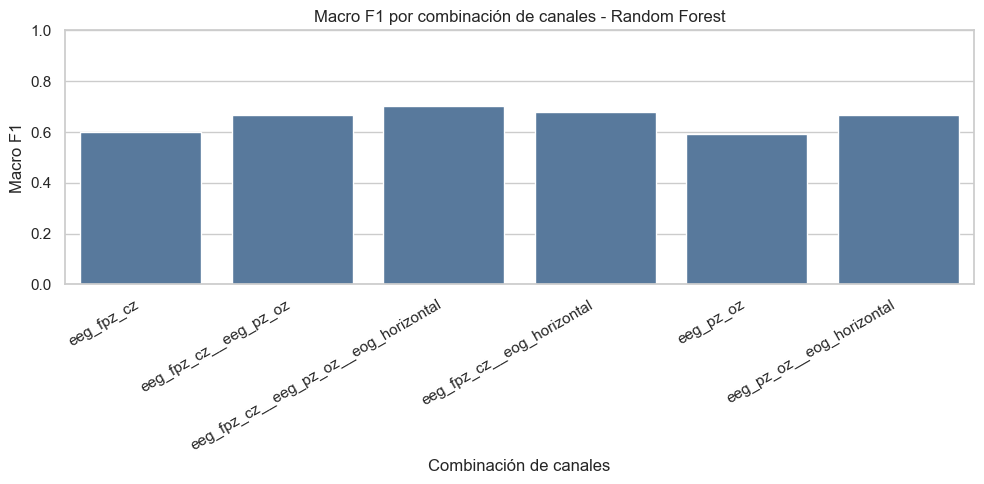

In [20]:
rf_y_pred, rf_metrics, rf_per_class = evaluate_global("Random Forest", rf_search)
rf_test_eval_df, rf_metrics_by_combo, rf_per_class_by_combo = evaluate_by_combo("Random Forest", rf_y_pred)

### Matriz de confusión global y por combinación

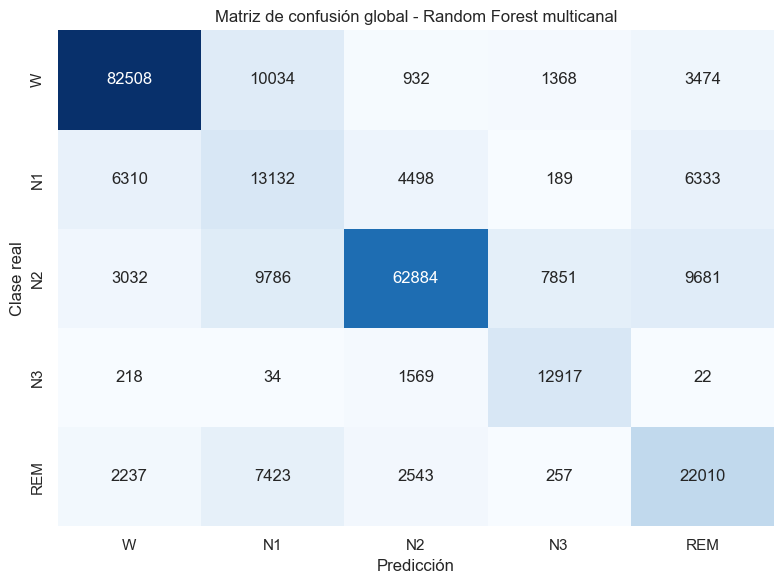

,W,N1,N2,N3,REM
W,82508,10034,932,1368,3474
N1,6310,13132,4498,189,6333
N2,3032,9786,62884,7851,9681
N3,218,34,1569,12917,22
REM,2237,7423,2543,257,22010


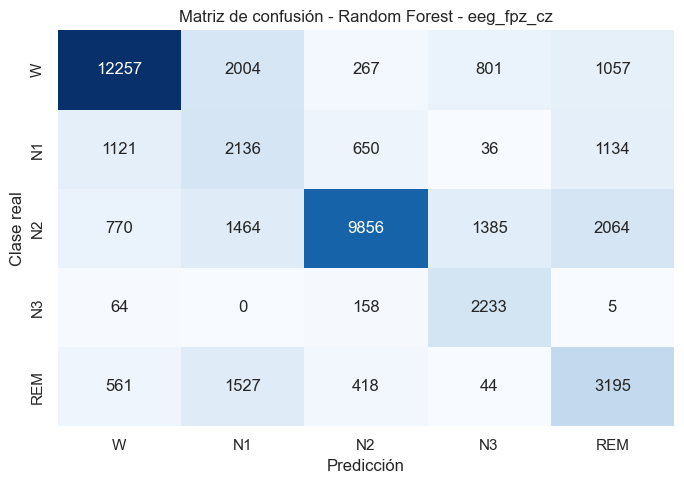

,W,N1,N2,N3,REM
W,12257,2004,267,801,1057
N1,1121,2136,650,36,1134
N2,770,1464,9856,1385,2064
N3,64,0,158,2233,5
REM,561,1527,418,44,3195


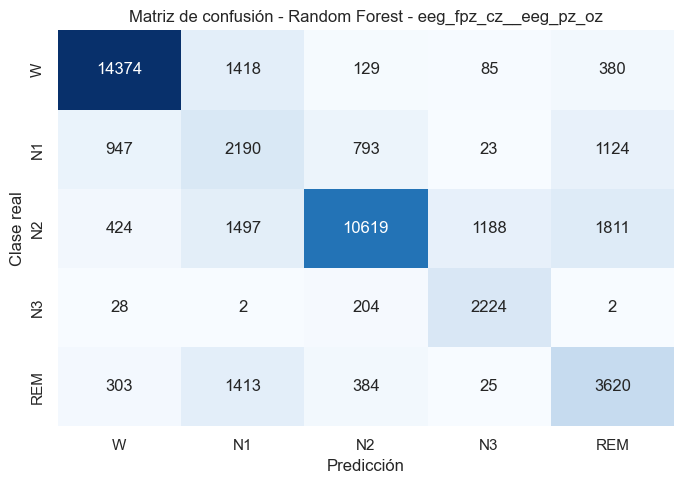

,W,N1,N2,N3,REM
W,14374,1418,129,85,380
N1,947,2190,793,23,1124
N2,424,1497,10619,1188,1811
N3,28,2,204,2224,2
REM,303,1413,384,25,3620


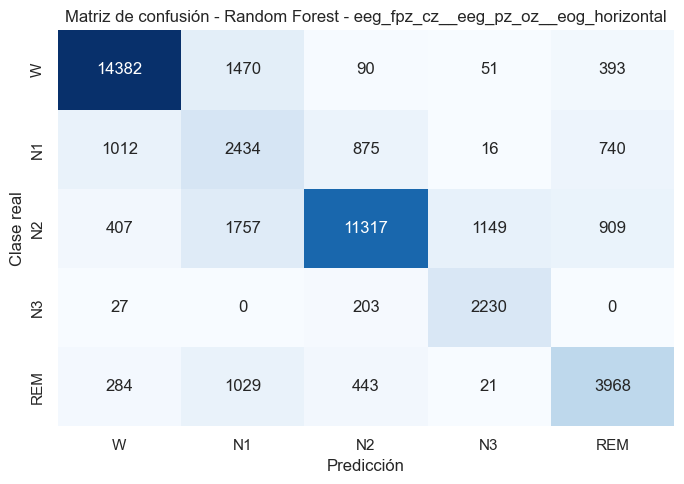

,W,N1,N2,N3,REM
W,14382,1470,90,51,393
N1,1012,2434,875,16,740
N2,407,1757,11317,1149,909
N3,27,0,203,2230,0
REM,284,1029,443,21,3968


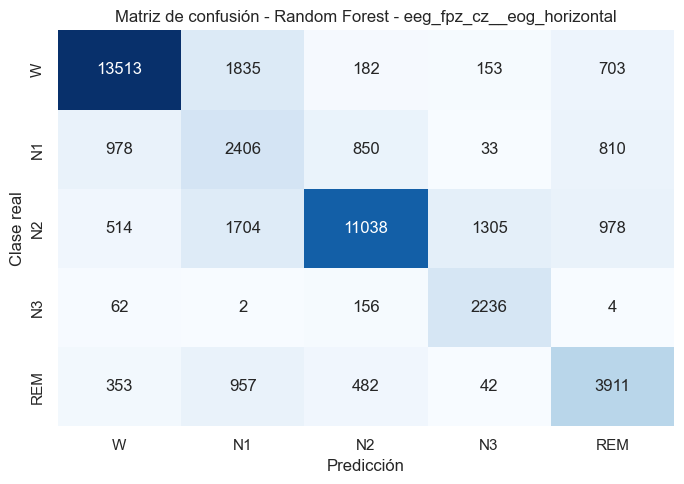

,W,N1,N2,N3,REM
W,13513,1835,182,153,703
N1,978,2406,850,33,810
N2,514,1704,11038,1305,978
N3,62,2,156,2236,4
REM,353,957,482,42,3911


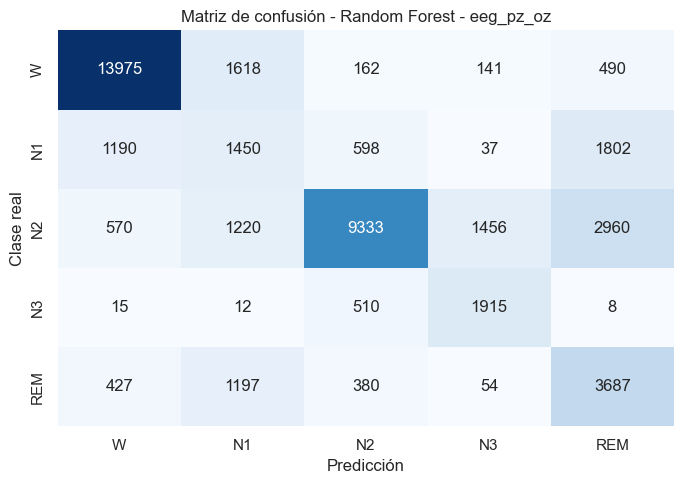

,W,N1,N2,N3,REM
W,13975,1618,162,141,490
N1,1190,1450,598,37,1802
N2,570,1220,9333,1456,2960
N3,15,12,510,1915,8
REM,427,1197,380,54,3687


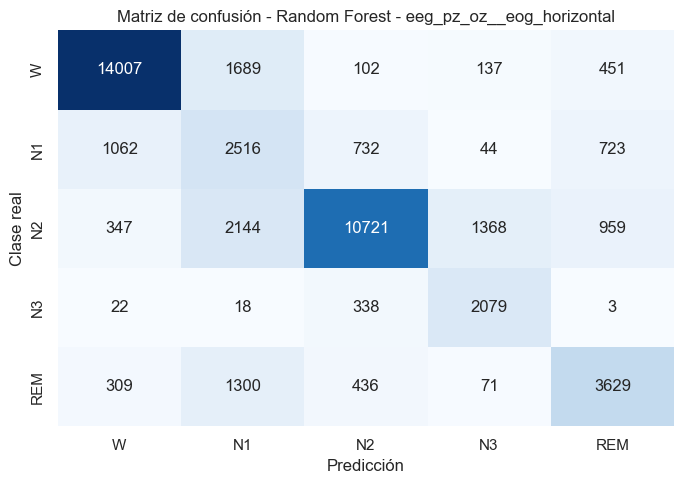

,W,N1,N2,N3,REM
W,14007,1689,102,137,451
N1,1062,2516,732,44,723
N2,347,2144,10721,1368,959
N3,22,18,338,2079,3
REM,309,1300,436,71,3629


In [21]:
plot_confusion_matrices("Random Forest", rf_test_eval_df)

### Importancia de variables y guardado de artefactos

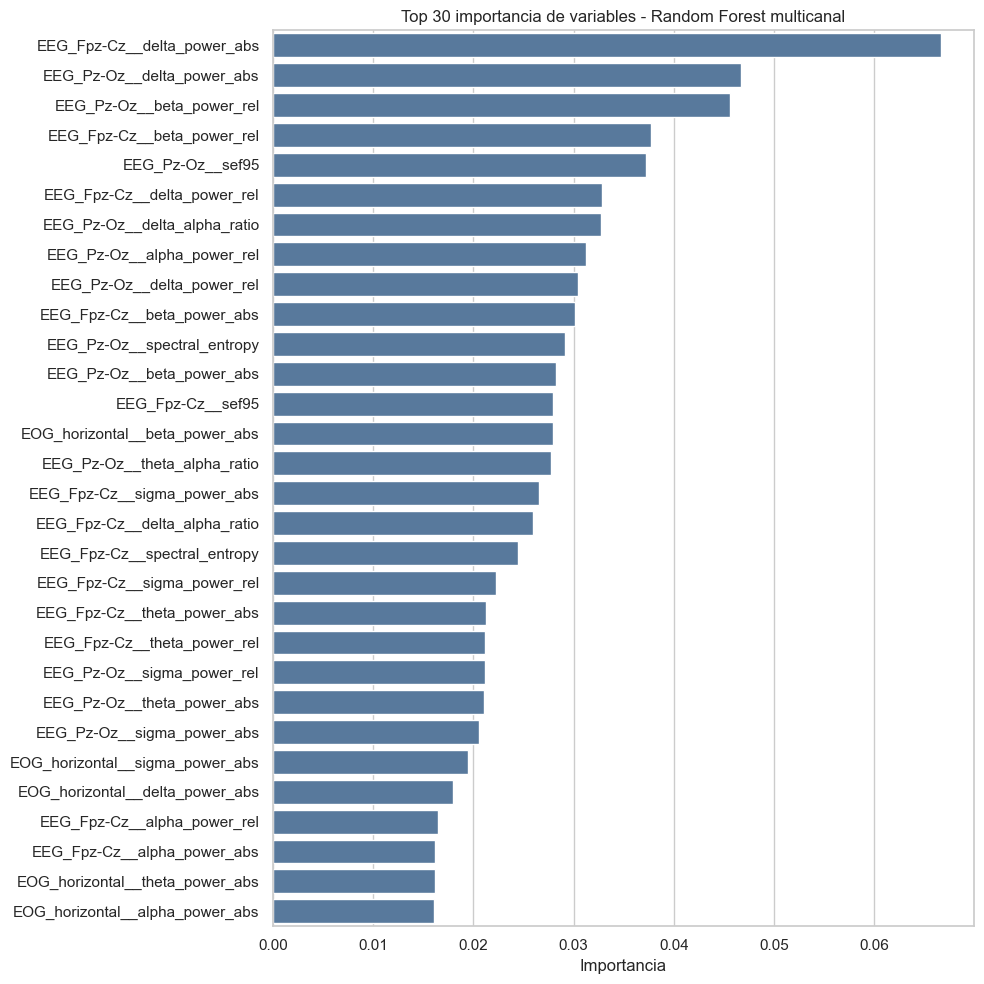

,feature,importance
9,EEG_Fpz-Cz__delta_power_abs,0.066621
23,EEG_Pz-Oz__delta_power_abs,0.046678
21,EEG_Pz-Oz__beta_power_rel,0.045616
7,EEG_Fpz-Cz__beta_power_rel,0.037709
25,EEG_Pz-Oz__sef95,0.037267
10,EEG_Fpz-Cz__delta_power_rel,0.032799
22,EEG_Pz-Oz__delta_alpha_ratio,0.032695
19,EEG_Pz-Oz__alpha_power_rel,0.031206
24,EEG_Pz-Oz__delta_power_rel,0.030445
6,EEG_Fpz-Cz__beta_power_abs,0.030157


Pipeline joblib guardado en: /Users/joelvargas/Documents/Estudio/MAIA/16_proyecto_despliegue_solucion/proyecto-despliegue-de-soluciones-G10/models/best-random-forest-multicanal.joblib
Info guardada en: /Users/joelvargas/Documents/Estudio/MAIA/16_proyecto_despliegue_solucion/proyecto-despliegue-de-soluciones-G10/models/model_info_random-forest_multicanal.json
Métricas por combinación guardadas en: /Users/joelvargas/Documents/Estudio/MAIA/16_proyecto_despliegue_solucion/proyecto-despliegue-de-soluciones-G10/models/metrics_by_channel_combo_random-forest_multicanal.csv


In [22]:
rf_feature_importance = plot_feature_importance("Random Forest", rf_search.best_estimator_)

rf_paths = save_artifacts(
    "Random Forest",
    "random-forest",
    rf_search,
    rf_metrics,
    rf_metrics_by_combo,
    rf_per_class_by_combo,
    rf_feature_importance,
)

## Modelo 4: Árbol de Decisión

Modelo base interpretable de un solo árbol. Se exploran criterio de división, profundidad, tamaños mínimos de división/hoja y número de variables por división.

### Búsqueda de hiperparámetros

In [23]:
dt_model = DecisionTreeClassifier(
    random_state=RANDOM_STATE,
)

dt_param_distributions = {
    "criterion": ["gini", "entropy"],
    "max_depth": [5, 8, 10, 15, 20, None],
    "min_samples_split": [2, 10, 50, 100],
    "min_samples_leaf": [1, 5, 20, 50, 100],
    "max_features": [None, "sqrt", 0.5],
}

dt_search = run_search("Decision Tree", dt_model, dt_param_distributions)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
[CV] END criterion=gini, max_depth=20, max_features=0.5, min_samples_leaf=20, min_samples_split=50; total time=  21.6s
[CV] END criterion=gini, max_depth=20, max_features=0.5, min_samples_leaf=20, min_samples_split=50; total time=  21.8s
[CV] END criterion=gini, max_depth=20, max_features=0.5, min_samples_leaf=20, min_samples_split=50; total time=  21.8s
[CV] END criterion=gini, max_depth=20, max_features=0.5, min_samples_leaf=20, min_samples_split=50; total time=  21.9s
[CV] END criterion=gini, max_depth=20, max_features=0.5, min_samples_leaf=20, min_samples_split=50; total time=  22.8s
[CV] END criterion=gini, max_depth=None, max_features=0.5, min_samples_leaf=1, min_samples_split=2; total time=  26.7s
[CV] END criterion=gini, max_depth=None, max_features=0.5, min_samples_leaf=1, min_samples_split=2; total time=  26.6s
[CV] END criterion=gini, max_depth=None, max_features=0.5, min_samples_leaf=1, min_samples_split=2; total 

{'min_samples_split': 2,
 'min_samples_leaf': 50,
 'max_features': 0.5,
 'max_depth': 20,
 'criterion': 'gini'}

In [24]:
dt_cv_results = show_cv_results(dt_search)

,rank_test_score,mean_test_score,std_test_score,mean_train_score,std_train_score,params
8,1,0.624616,0.016157,0.750913,0.004200,"{'min_samples_split': 2, 'min_samples_leaf': 5..."
1,2,0.619390,0.016479,0.776196,0.003485,"{'min_samples_split': 50, 'min_samples_leaf': ..."
3,3,0.618239,0.012893,0.710192,0.003002,"{'min_samples_split': 50, 'min_samples_leaf': ..."
5,4,0.567398,0.024057,0.614449,0.011751,"{'min_samples_split': 10, 'min_samples_leaf': ..."
6,5,0.567290,0.023932,0.614269,0.011743,"{'min_samples_split': 100, 'min_samples_leaf':..."
0,6,0.543860,0.021166,1.000000,0.000000,"{'min_samples_split': 2, 'min_samples_leaf': 1..."
7,7,0.541377,0.014156,0.587948,0.014651,"{'min_samples_split': 10, 'min_samples_leaf': ..."
4,8,0.536539,0.014576,0.566243,0.003691,"{'min_samples_split': 10, 'min_samples_leaf': ..."
9,9,0.463582,0.035159,0.480802,0.018532,"{'min_samples_split': 50, 'min_samples_leaf': ..."
2,10,0.448668,0.046620,0.467008,0.025633,"{'min_samples_split': 50, 'min_samples_leaf': ..."


### Evaluación global en test y por combinación de canales

=== Decision Tree - evaluación global en test ===


accuracy                                                      0.643197
macro_f1                                                       0.59179
balanced_accuracy                                             0.637746
cohens_kappa                                                  0.528465
best_cv_macro_f1                                              0.624616
best_params          {'min_samples_split': 2, 'min_samples_leaf': 5...
Name: value, dtype: object

,class,precision_per_class,recall_per_class,f1_per_class,support
0,W,0.862792,0.778256,0.818347,98316
1,N1,0.254964,0.434607,0.321386,30462
2,N2,0.859328,0.558037,0.676659,93234
3,N3,0.519293,0.821545,0.636352,14760
4,REM,0.439771,0.596287,0.506206,34470


              precision    recall  f1-score   support

           W       0.25      0.43      0.32     30462
          N1       0.86      0.56      0.68     93234
          N2       0.52      0.82      0.64     14760
          N3       0.44      0.60      0.51     34470
         REM       0.86      0.78      0.82     98316

    accuracy                           0.64    271242
   macro avg       0.59      0.64      0.59    271242
weighted avg       0.72      0.64      0.66    271242



,channel_combo,support,accuracy,macro_f1,balanced_accuracy,cohens_kappa
1,eeg_fpz_cz,45207,0.611166,0.563383,0.618387,0.490465
2,eeg_fpz_cz__eeg_pz_oz,45207,0.649899,0.594333,0.639319,0.535568
3,eeg_fpz_cz__eeg_pz_oz__eog_horizontal,45207,0.677439,0.626781,0.672669,0.570505
4,eeg_fpz_cz__eog_horizontal,45207,0.661623,0.617519,0.664668,0.551577
5,eeg_pz_oz,45207,0.603468,0.545570,0.585724,0.478919
6,eeg_pz_oz__eog_horizontal,45207,0.655584,0.605329,0.645710,0.544767
0,overall,271242,0.643197,0.591790,0.637746,0.528465


,channel_combo,class,precision_per_class,recall_per_class,f1_per_class,support
1,eeg_fpz_cz,N1,0.248250,0.426039,0.313706,5077
2,eeg_fpz_cz,N2,0.864279,0.566767,0.684597,15539
3,eeg_fpz_cz,N3,0.469904,0.853659,0.606148,2460
4,eeg_fpz_cz,REM,0.385169,0.549695,0.452955,5745
0,eeg_fpz_cz,W,0.836096,0.695777,0.759510,16386
6,eeg_fpz_cz__eeg_pz_oz,N1,0.256963,0.425251,0.320350,5077
7,eeg_fpz_cz__eeg_pz_oz,N2,0.871988,0.558916,0.681203,15539
8,eeg_fpz_cz__eeg_pz_oz,N3,0.542425,0.860163,0.665304,2460
9,eeg_fpz_cz__eeg_pz_oz,REM,0.412681,0.539252,0.467552,5745
5,eeg_fpz_cz__eeg_pz_oz,W,0.862992,0.813011,0.837256,16386


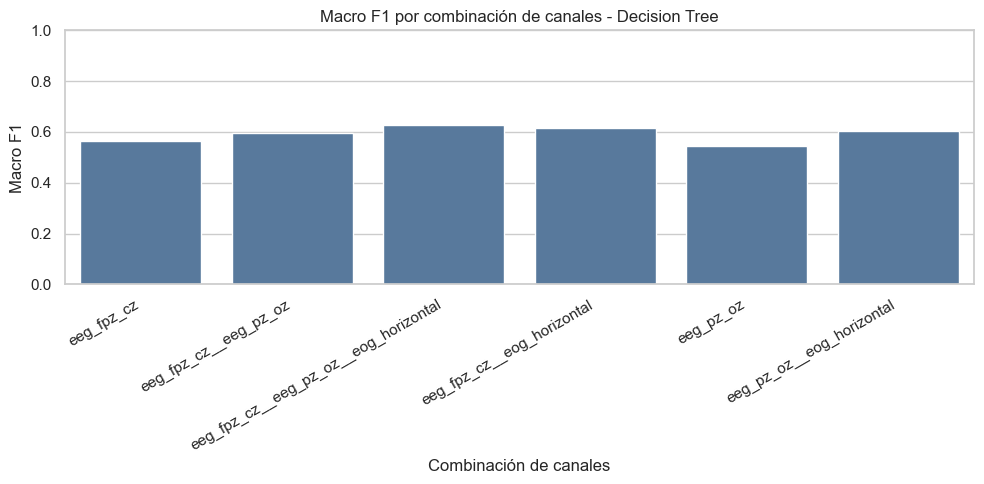

In [25]:
dt_y_pred, dt_metrics, dt_per_class = evaluate_global("Decision Tree", dt_search)
dt_test_eval_df, dt_metrics_by_combo, dt_per_class_by_combo = evaluate_by_combo("Decision Tree", dt_y_pred)

### Matriz de confusión global y por combinación

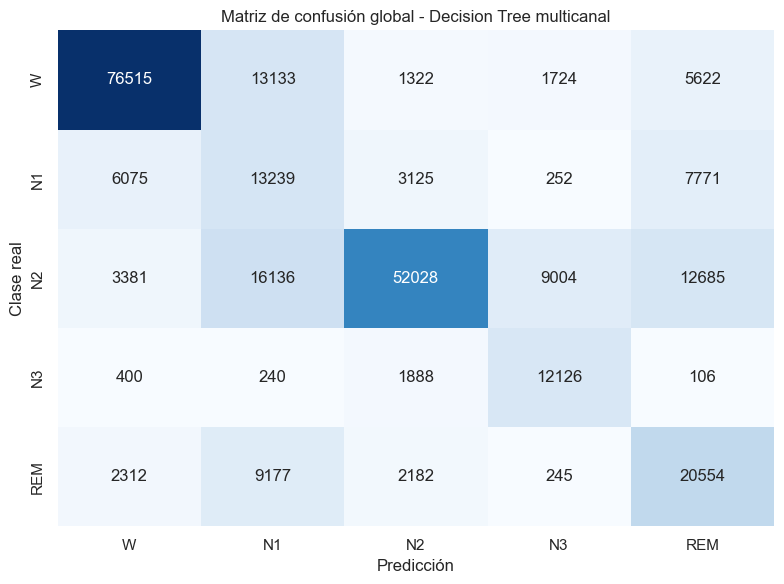

,W,N1,N2,N3,REM
W,76515,13133,1322,1724,5622
N1,6075,13239,3125,252,7771
N2,3381,16136,52028,9004,12685
N3,400,240,1888,12126,106
REM,2312,9177,2182,245,20554


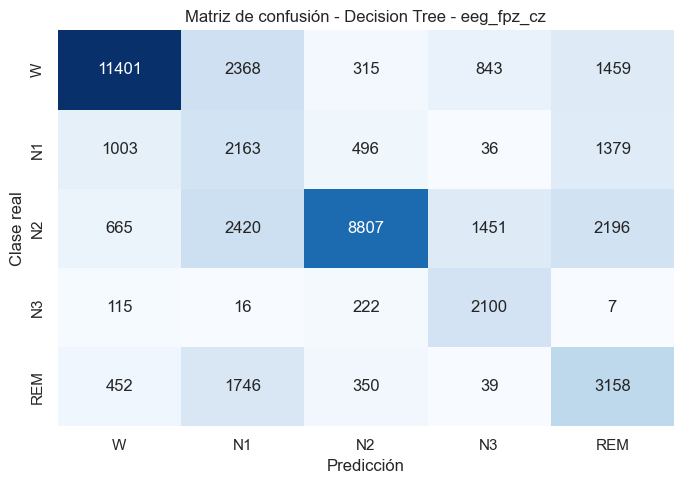

,W,N1,N2,N3,REM
W,11401,2368,315,843,1459
N1,1003,2163,496,36,1379
N2,665,2420,8807,1451,2196
N3,115,16,222,2100,7
REM,452,1746,350,39,3158


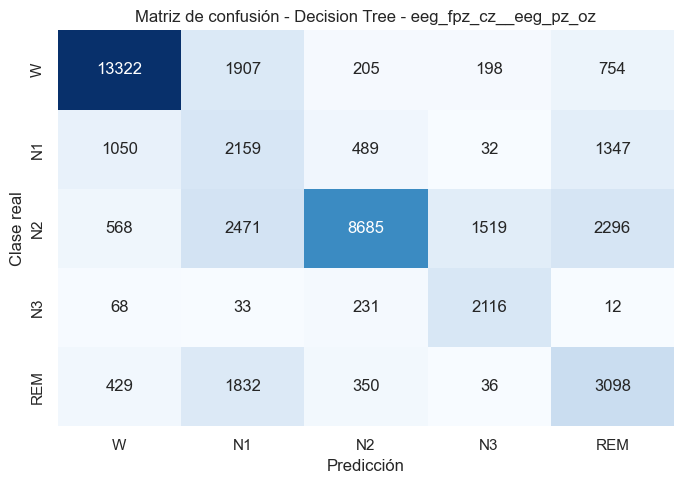

,W,N1,N2,N3,REM
W,13322,1907,205,198,754
N1,1050,2159,489,32,1347
N2,568,2471,8685,1519,2296
N3,68,33,231,2116,12
REM,429,1832,350,36,3098


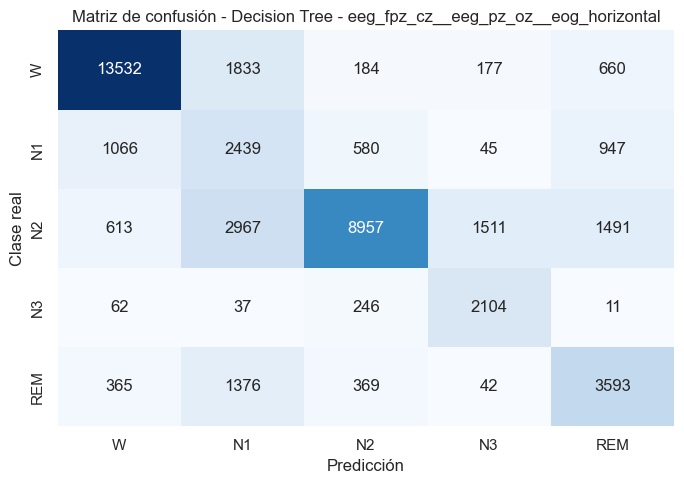

,W,N1,N2,N3,REM
W,13532,1833,184,177,660
N1,1066,2439,580,45,947
N2,613,2967,8957,1511,1491
N3,62,37,246,2104,11
REM,365,1376,369,42,3593


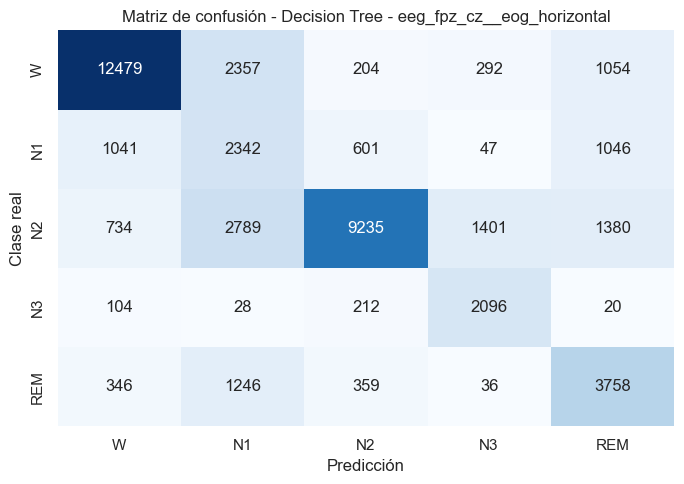

,W,N1,N2,N3,REM
W,12479,2357,204,292,1054
N1,1041,2342,601,47,1046
N2,734,2789,9235,1401,1380
N3,104,28,212,2096,20
REM,346,1246,359,36,3758


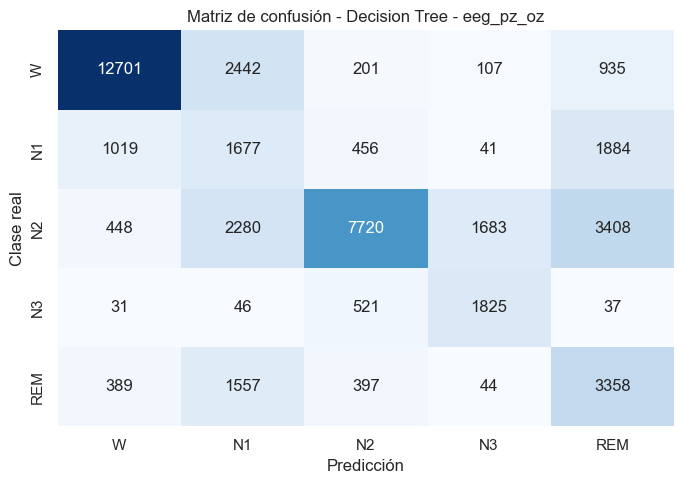

,W,N1,N2,N3,REM
W,12701,2442,201,107,935
N1,1019,1677,456,41,1884
N2,448,2280,7720,1683,3408
N3,31,46,521,1825,37
REM,389,1557,397,44,3358


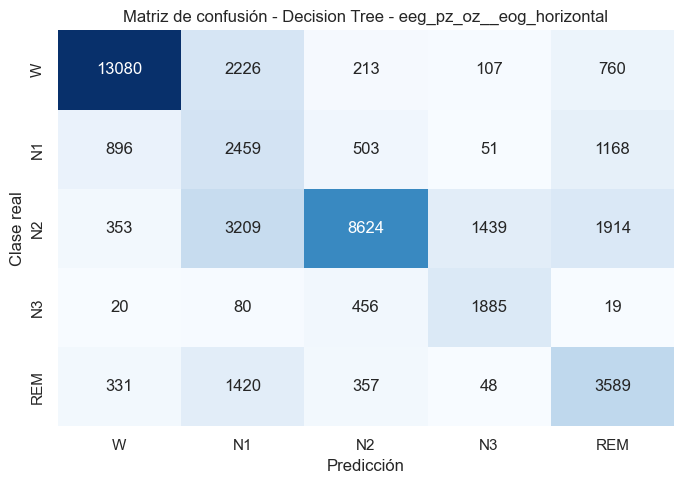

,W,N1,N2,N3,REM
W,13080,2226,213,107,760
N1,896,2459,503,51,1168
N2,353,3209,8624,1439,1914
N3,20,80,456,1885,19
REM,331,1420,357,48,3589


In [26]:
plot_confusion_matrices("Decision Tree", dt_test_eval_df)

### Importancia de variables y guardado de artefactos

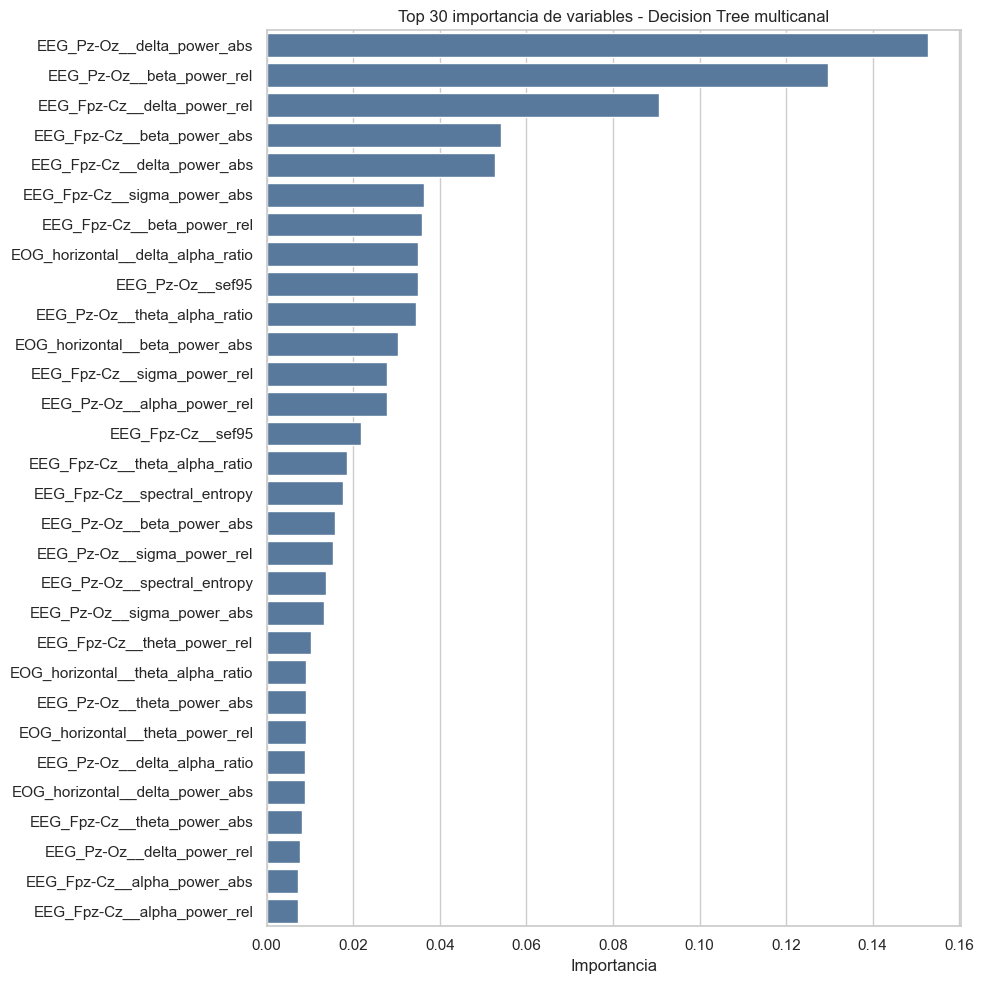

,feature,importance
23,EEG_Pz-Oz__delta_power_abs,1.527395e-01
21,EEG_Pz-Oz__beta_power_rel,1.297090e-01
10,EEG_Fpz-Cz__delta_power_rel,9.056942e-02
6,EEG_Fpz-Cz__beta_power_abs,5.412012e-02
9,EEG_Fpz-Cz__delta_power_abs,5.284022e-02
12,EEG_Fpz-Cz__sigma_power_abs,3.625935e-02
7,EEG_Fpz-Cz__beta_power_rel,3.585812e-02
36,EOG_horizontal__delta_alpha_ratio,3.494169e-02
25,EEG_Pz-Oz__sef95,3.486562e-02
29,EEG_Pz-Oz__theta_alpha_ratio,3.451590e-02


Pipeline joblib guardado en: /Users/joelvargas/Documents/Estudio/MAIA/16_proyecto_despliegue_solucion/proyecto-despliegue-de-soluciones-G10/models/best-decision-tree-multicanal.joblib
Info guardada en: /Users/joelvargas/Documents/Estudio/MAIA/16_proyecto_despliegue_solucion/proyecto-despliegue-de-soluciones-G10/models/model_info_decision-tree_multicanal.json
Métricas por combinación guardadas en: /Users/joelvargas/Documents/Estudio/MAIA/16_proyecto_despliegue_solucion/proyecto-despliegue-de-soluciones-G10/models/metrics_by_channel_combo_decision-tree_multicanal.csv


In [27]:
dt_feature_importance = plot_feature_importance("Decision Tree", dt_search.best_estimator_)

dt_paths = save_artifacts(
    "Decision Tree",
    "decision-tree",
    dt_search,
    dt_metrics,
    dt_metrics_by_combo,
    dt_per_class_by_combo,
    dt_feature_importance,
)

## Comparación de modelos

Resumen de las métricas en test y del mejor `f1_macro` de validación cruzada para los cuatro modelos. El ranking se ordena por `macro_f1` en test.

,model,best_cv_macro_f1,accuracy,macro_f1,balanced_accuracy,cohens_kappa,best_params
0,Random Forest,0.675976,0.713204,0.651516,0.691689,0.613213,"{'n_estimators': 100, 'min_samples_split': 10,..."
1,LightGBM,0.684530,0.711885,0.651369,0.696422,0.612990,"{'reg_lambda': 0, 'reg_alpha': 0.01, 'num_leav..."
2,XGBoost,0.683577,0.710627,0.650126,0.696026,0.611487,"{'n_estimators': 500, 'max_depth': 5, 'learnin..."
3,Decision Tree,0.624616,0.643197,0.591790,0.637746,0.528465,"{'min_samples_split': 2, 'min_samples_leaf': 5..."


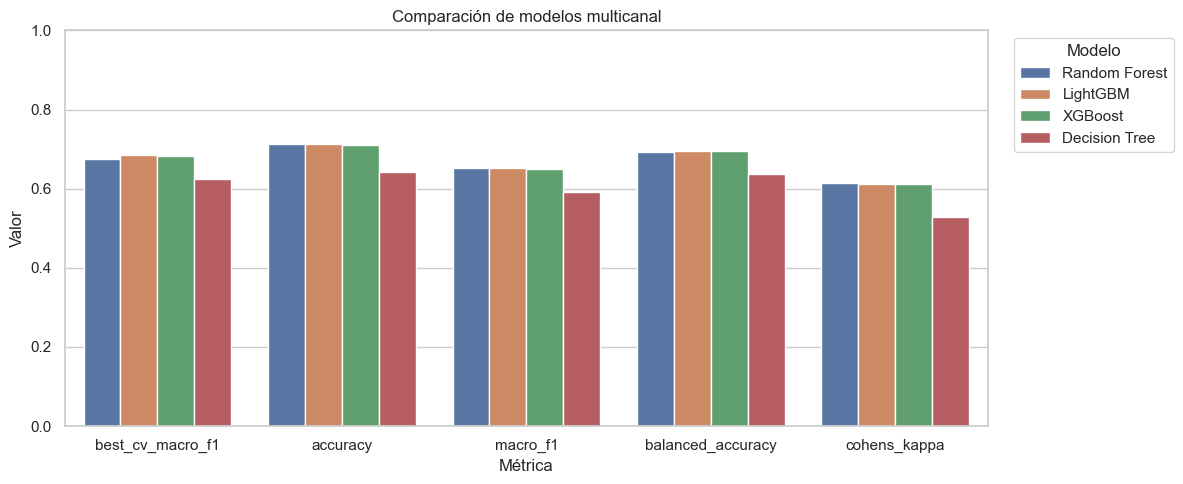

Mejor modelo por macro F1 en test: Random Forest (0.6515)


In [30]:
comparison = pd.DataFrame(
    [
        {
            "model": model_name,
            "best_cv_macro_f1": result["metrics"]["best_cv_macro_f1"],
            "accuracy": result["metrics"]["accuracy"],
            "macro_f1": result["metrics"]["macro_f1"],
            "balanced_accuracy": result["metrics"]["balanced_accuracy"],
            "cohens_kappa": result["metrics"]["cohens_kappa"],
            "best_params": result["metrics"]["best_params"],
        }
        for model_name, result in results.items()
    ]
).sort_values("macro_f1", ascending=False).reset_index(drop=True)

comparison.to_csv(COMPARISON_PATH, index=False)
display(comparison)

comparison_long = comparison.melt(
    id_vars="model",
    value_vars=["best_cv_macro_f1", "accuracy", "macro_f1", "balanced_accuracy", "cohens_kappa"],
    var_name="metric",
    value_name="value",
)

plt.figure(figsize=(12, 5))
sns.barplot(data=comparison_long, x="metric", y="value", hue="model")
plt.title("Comparación de modelos multicanal")
plt.xlabel("Métrica")
plt.ylabel("Valor")
plt.ylim(0, 1)
plt.legend(title="Modelo", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

best_model_name = comparison.loc[0, "model"]
print(f"Mejor modelo por macro F1 en test: {best_model_name} ({comparison.loc[0, 'macro_f1']:.4f})")

model,Decision Tree,LightGBM,Random Forest,XGBoost
channel_combo,,,,
eeg_fpz_cz,0.563383,0.606261,0.599128,0.601625
eeg_fpz_cz__eeg_pz_oz,0.594333,0.666861,0.668496,0.665258
eeg_fpz_cz__eeg_pz_oz__eog_horizontal,0.626781,0.705797,0.704300,0.704946
eeg_fpz_cz__eog_horizontal,0.617519,0.682632,0.678910,0.681151
eeg_pz_oz,0.545570,0.584984,0.593999,0.585462
eeg_pz_oz__eog_horizontal,0.605329,0.663554,0.668354,0.663100
overall,0.591790,0.651369,0.651516,0.650126


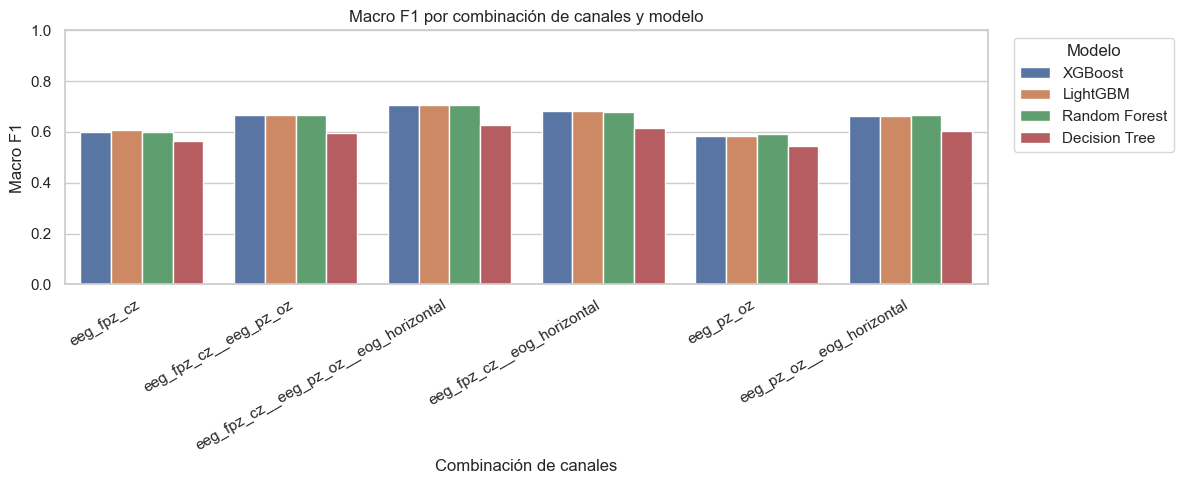

In [31]:
comparison_by_combo = pd.concat(
    [
        result["metrics_by_combo"].assign(model=model_name)
        for model_name, result in results.items()
    ],
    ignore_index=True,
)
comparison_by_combo.to_csv(COMPARISON_BY_COMBO_PATH, index=False)

display(
    comparison_by_combo.pivot(index="channel_combo", columns="model", values="macro_f1")
)

plt.figure(figsize=(12, 5))
sns.barplot(
    data=comparison_by_combo[comparison_by_combo["channel_combo"] != "overall"],
    x="channel_combo",
    y="macro_f1",
    hue="model",
)
plt.title("Macro F1 por combinación de canales y modelo")
plt.xlabel("Combinación de canales")
plt.ylabel("Macro F1")
plt.xticks(rotation=30, ha="right")
plt.ylim(0, 1)
plt.legend(title="Modelo", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## Registro en MLflow

Cada modelo se registra como un *run* en el experimento `sleep-staging-baseline-multicanal`, el mismo que usa `09_best_model_xgboost_multicanal.ipynb`. Los datos se leen de los artefactos guardados arriba (`.joblib` y `model_info_<modelo>_multicanal.json`), así que no hace falta reentrenar. Basta con ejecutar antes las celdas de configuración, carga y preparación de matrices.

Por cada modelo se registran:

- **Parámetros:** mejores hiperparámetros y configuración de la búsqueda.
- **Métricas:** globales en test, `best_cv_macro_f1` y métricas por combinación de canales (p. ej. `macro_f1__eeg_pz_oz`).
- **Artefactos:** matriz de confusión, CSV/JSON de métricas e importancia de variables y el bundle `.joblib` de inferencia.
- **Modelo:** en formato `mlflow.sklearn` (serializado con `cloudpickle`) y registrado en el Model Registry como `sleep-staging-<modelo>-multicanal`.

Se usa `mlflow.sklearn.log_model` también para XGBoost porque `mlflow.xgboost.log_model` llama a `XGBClassifier.save_model()`, que falla con scikit-learn >= 1.8 (`_estimator_type` undefined).

**Requisitos:** `MLFLOW_TRACKING_URI` definido en `.env` (ver `.env.example`) y credenciales de AWS configuradas, porque el servidor guarda los artefactos en S3. Sin credenciales, parámetros y métricas se registran, pero la subida de artefactos falla.

In [ ]:
load_dotenv(PROJECT_ROOT / ".env")

MLFLOW_TRACKING_URI = os.getenv("MLFLOW_TRACKING_URI")
MLFLOW_EXPERIMENT_NAME = "sleep-staging-baseline-multicanal"
REGISTER_MODELS = True

# El nginx del servidor rechaza subidas grandes (413 Request Entity Too Large) y el
# Random Forest pesa cientos de MB. Con la subida multiparte, los archivos de más de
# 50 MB se suben por partes directo a S3 con URLs prefirmadas, sin pasar por nginx.
os.environ.setdefault("MLFLOW_ENABLE_PROXY_MULTIPART_UPLOAD", "true")
os.environ.setdefault("MLFLOW_MULTIPART_UPLOAD_MINIMUM_FILE_SIZE", str(50 * 1024**2))
os.environ.setdefault("MLFLOW_HTTP_REQUEST_TIMEOUT", "600")
os.environ.setdefault("MLFLOW_ARTIFACT_UPLOAD_DOWNLOAD_TIMEOUT", "1800")

# Los .joblib más grandes que esto no se suben como artefacto extra: el modelo ya
# queda en MLflow con `log_model` y así no se sube dos veces.
MAX_EXTRA_ARTIFACT_MB = 100

MODELS_TO_LOG = {
    "XGBoost": "xgboost",
    "LightGBM": "lightgbm",
    "Random Forest": "random-forest",
    "Decision Tree": "decision-tree",
}

mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)
experiment = mlflow.set_experiment(MLFLOW_EXPERIMENT_NAME)

print(f"Tracking URI: {MLFLOW_TRACKING_URI}")
print(f"Experiment: {experiment.name}")

Tracking URI: https://18.119.196.100
Experiment: sleep-staging-baseline-multicanal


In [ ]:
mlflow_label_ids = label_encoder.transform(class_labels)
combo_metric_names = ["accuracy", "macro_f1", "balanced_accuracy", "cohens_kappa"]
mlflow_runs = {}
mlflow_failed = {}

for model_name, model_slug in MODELS_TO_LOG.items():
    paths = get_artifact_paths(model_slug)
    if not paths["joblib"].exists():
        print(f"[{model_name}] No se encontró {paths['joblib']}; se omite.")
        continue

    bundle = joblib.load(paths["joblib"])
    with open(paths["info"]) as f:
        info = json.load(f)

    model = bundle["model"]
    y_pred_mlflow = model.predict(X_test[bundle["feature_columns"]])

    try:
        with mlflow.start_run(experiment_id=experiment.experiment_id, run_name=f"{model_slug}_multicanal") as run:
            mlflow.set_tags(
                {
                    "model_type": "baseline",
                    "model_family": model_name,
                    "signals_used": "EEG Fpz-Cz y/o EEG Pz-Oz + EOG horizontal (opcional)",
                    "stage": "hyperparameter_search",
                    "notebook": "08_train_base_models_multichannel",
                }
            )

            mlflow.log_params(info["best_params"])
            mlflow.log_params(
                {
                    "cv_splits": CV_SPLITS,
                    "n_iter_search": N_ITER_SEARCH,
                    "scoring": SCORING,
                    "num_class": len(class_labels),
                    "n_features": len(bundle["feature_columns"]),
                    "excluded_id_columns": ",".join(ID_COLUMNS),
                    "excluded_control_columns": ",".join(CONTROL_COLUMNS),
                    "categorical_columns": ",".join(CATEGORICAL_COLUMNS),
                }
            )

            mlflow.log_metrics(
                {
                    "accuracy": info["accuracy"],
                    "macro_f1": info["macro_f1"],
                    "balanced_accuracy": info["balanced_accuracy"],
                    "cohens_kappa": info["cohens_kappa"],
                    "best_cv_macro_f1": info["best_cv_macro_f1"],
                }
            )

            for row in info["metrics_by_channel_combo"]:
                if row["channel_combo"] == "overall":
                    continue
                mlflow.log_metrics(
                    {f"{metric}__{row['channel_combo']}": row[metric] for metric in combo_metric_names}
                )

            conf_matrix_df = pd.DataFrame(
                confusion_matrix(y_test, y_pred_mlflow, labels=mlflow_label_ids),
                index=class_labels,
                columns=class_labels,
            )
            fig, ax = plt.subplots(figsize=(8, 6))
            sns.heatmap(conf_matrix_df, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
            ax.set_title(f"Matriz de confusión - {model_name} multicanal")
            ax.set_xlabel("Predicción")
            ax.set_ylabel("Clase real")
            fig.tight_layout()
            mlflow.log_figure(fig, "confusion_matrix_test.png")
            plt.close(fig)

            for artifact_key in ["info", "metrics_by_combo", "per_class_by_combo", "feature_importance", "joblib"]:
                artifact_mb = paths[artifact_key].stat().st_size / 1024**2
                if artifact_key == "joblib" and artifact_mb > MAX_EXTRA_ARTIFACT_MB:
                    print(f"[{model_name}] Se omite {paths[artifact_key].name} ({artifact_mb:.0f} MB) como artefacto extra.")
                    continue
                mlflow.log_artifact(str(paths[artifact_key]), artifact_path="files")

            # cloudpickle: el formato por defecto (skops) rechaza los tipos internos de los
            # árboles y de los boosters de XGBoost/LightGBM. Los modelos son propios, igual
            # que el bundle .joblib, que también es pickle.
            mlflow.sklearn.log_model(
                sk_model=model,
                name="model",
                serialization_format=mlflow.sklearn.SERIALIZATION_FORMAT_CLOUDPICKLE,
                input_example=X_test[bundle["feature_columns"]].head(5),
                registered_model_name=f"sleep-staging-{model_slug}-multicanal" if REGISTER_MODELS else None,
            )

            mlflow_runs[model_name] = run.info.run_id
            print(f"[{model_name}] registrado en MLflow. run_id: {run.info.run_id}")
    except Exception as exc:
        mlflow_failed[model_name] = f"{type(exc).__name__}: {exc}"
        print(f"[{model_name}] falló el registro: {mlflow_failed[model_name][:500]}")

display(pd.Series(mlflow_runs, name="run_id"))
if mlflow_failed:
    display(pd.Series(mlflow_failed, name="error"))

[Random Forest] Se omite best-random-forest-multicanal.joblib (376 MB) como artefacto extra.


2026/10/28 20:27:56 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
Successfully registered model 'sleep-staging-random-forest-multicanal'.
2026/10/28 20:28:21 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: sleep-staging-random-forest-multicanal, version 1
Created version '1' of model 'sleep-staging-random-forest-multicanal'.


[Random Forest] registrado en MLflow. run_id: 5281aafcfb154fee82af28b47cd8fafa
🏃 View run random-forest_multicanal at: https://18.119.196.100/#/experiments/4/runs/5281aafcfb154fee82af28b47cd8fafa
🧪 View experiment at: https://18.119.196.100/#/experiments/4


2026/10/28 20:28:30 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
Successfully registered model 'sleep-staging-decision-tree-multicanal'.
2026/10/28 20:28:34 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: sleep-staging-decision-tree-multicanal, version 1
Created version '1' of model 'sleep-staging-decision-tree-multicanal'.


[Decision Tree] registrado en MLflow. run_id: 9ce6a4906c1848d3b709a000f59e74f5
🏃 View run decision-tree_multicanal at: https://18.119.196.100/#/experiments/4/runs/9ce6a4906c1848d3b709a000f59e74f5
🧪 View experiment at: https://18.119.196.100/#/experiments/4


Random Forest    5281aafcfb154fee82af28b47cd8fafa
Decision Tree    9ce6a4906c1848d3b709a000f59e74f5
Name: run_id, dtype: object